## Fuente de datos inicial

### Conexión a la fuente de datos

In [1]:
# =============================================================================
# 1.1 Importar librerías
# =============================================================================
# Rutas globales y paquetes python
import sys
from pathlib import Path

from configparser import ConfigParser
from datetime import datetime

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn - Feature Selection
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

#--- Configuración de visualización ---#
from IPython.display import display, Markdown
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
plt.style.use('seaborn-v0_8-whitegrid')

# Agregar 'src' al path para importar módulos del proyecto
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.db.connection import PostgresConnection

print(f"✓ Librerías importadas correctamente")
print(f"✓ Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

✓ Librerías importadas correctamente
✓ Fecha de ejecución: 2026-09-05 14:49:56


In [312]:
# =============================================================================
# 1.2 Establecer conexión a PostgreSQL
# =============================================================================
config_path = project_root / 'configs' / 'database.ini'

config = ConfigParser()
config.read(config_path)

pg_conn = PostgresConnection(
    host=config.get('postgres', 'host'),
    port=config.getint('postgres', 'port'),
    dbname=config.get('postgres', 'dbname'),
    user=config.get('postgres', 'user'),
    password=config.get('postgres', 'password')
)
conn = pg_conn.connect()

print(f"✓ Conexión establecida exitosamente")
print(f"  Base de datos: {pg_conn.dbname}")
print(f"  Host: {pg_conn.host}:{pg_conn.port}")

✓ Conexión establecida exitosamente
  Base de datos: postgres
  Host: localhost:5432


In [2]:
TARGET = "flg_opa_incumplimiento_contractual"
DATE_COL = "fecha_inicio_obra"

gold_path = project_root / "data" / "gold" / "ds_op_inco_igeip.csv"
df_raw = pd.read_csv(gold_path, encoding="utf-8", low_memory=False)

In [313]:
# =============================================================================
# 1.3 Cargar datos desde la capa Silver
# =============================================================================
TABLA_ORIGEN = "r$_ds_obras_publicas_infobras"

query = f"SELECT * FROM {TABLA_ORIGEN}"
df_raw = pd.read_sql(query, conn)

print(f"  Datos cargados desde: {TABLA_ORIGEN}")
print(f"  - Registros: {len(df_raw):,}")
print(f"  - Columnas: {len(df_raw.columns)}")
print(f"  - Memoria: {df_raw.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

C:\Users\yanfr\AppData\Local\Temp\ipykernel_29256\739730419.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_raw = pd.read_sql(query, conn)


  Datos cargados desde: r$_ds_obras_publicas_infobras
  - Registros: 69,952
  - Columnas: 130
  - Memoria: 284.56 MB


### 1. Filtros funcionales

In [3]:
# =============================================================================
# 1.4 Filtrar por caracteristicas funcionales y de negocio
# =============================================================================

NIVEL_GOBIERNO_FILTRO = 'GOBIERNO NACIONAL'  # Opciones: 'GOBIERNO NACIONAL', 'GOBIERNO REGIONAL', 'GOBIERNO LOCAL'
MARCO = 'INVIERTE'

# Verificar valores únicos antes del filtro
print("Distribución por Nivel de Gobierno (antes del filtro)")
print("=" * 60)
print(df_raw['nivel_gobierno'].value_counts())
print()

# Aplicar filtro
df = df_raw[(df_raw['nivel_gobierno'] == NIVEL_GOBIERNO_FILTRO) & (df_raw['marco'] == MARCO)].copy()

print(f"Filtro aplicado: nivel_gobierno == '{NIVEL_GOBIERNO_FILTRO}'")
print(f"Filtro aplicado: marco == '{MARCO}'")
print(f" - Registros después del filtro: {len(df):,}")

# Verificar distribución del target después del filtro
if 'flg_opa_incumplimiento_contractual' in df_raw.columns:
    print(f"\nDistribución del target después del filtro:")
    print(df['flg_opa_incumplimiento_contractual'].value_counts())
    print(f"  Tasa de paralización: {df['flg_opa_incumplimiento_contractual'].mean()*100:.2f}%")

Distribución por Nivel de Gobierno (antes del filtro)
nivel_gobierno
GOBIERNO LOCAL       55582
GOBIERNO NACIONAL     7367
GOBIERNO REGIONAL     6998
Name: count, dtype: int64

Filtro aplicado: nivel_gobierno == 'GOBIERNO NACIONAL'
Filtro aplicado: marco == 'INVIERTE'
 - Registros después del filtro: 2,646

Distribución del target después del filtro:
flg_opa_incumplimiento_contractual
0    2449
1     197
Name: count, dtype: int64
  Tasa de paralización: 7.45%


In [4]:
#print(*df.columns, sep="\n")
for col in df.columns:
    print(f"{col}: {df[col].dtype}, Nulos: {df[col].isnull().sum()}, Únicos: {df[col].nunique()}")

codigo_entidad: float64, Nulos: 0, Únicos: 165
entidad_publica: str, Nulos: 0, Únicos: 165
codigo_infobras: int64, Nulos: 0, Únicos: 2646
nombre_obra: str, Nulos: 0, Únicos: 2635
modalidad_ejecucion_obra: str, Nulos: 0, Únicos: 1
flg_corresponde_saldo_obra: bool, Nulos: 0, Únicos: 2
codigo_infobras_obra_inicial: float64, Nulos: 2559, Únicos: 83
naturaleza_obra: str, Nulos: 0, Únicos: 14
tipo_obra_nivel_1: str, Nulos: 0, Únicos: 9
tipo_obra_nivel_2: str, Nulos: 0, Únicos: 36
tipo_obra_nivel_3: str, Nulos: 0, Únicos: 66
estado_ejecucion: str, Nulos: 0, Únicos: 3
flg_reconstruccion_con_cambios: bool, Nulos: 0, Únicos: 2
flg_reactivacion_economica: bool, Nulos: 0, Únicos: 1
otra_marca: float64, Nulos: 2646, Únicos: 0
n_informes_monitores_ciudadanos: int64, Nulos: 0, Únicos: 1
n_denuncias_viculadas: float64, Nulos: 2646, Únicos: 0
n_informes_control: int64, Nulos: 0, Únicos: 24
n_comentarios_ciudadanos: int64, Nulos: 0, Únicos: 3
flg_obra_caracter_reservado: bool, Nulos: 0, Únicos: 1
nivel_

### 2. Pre-seleccion de variables

In [10]:
# Definir la lista de columnas relevantes
columnas_interes = ['codigo_entidad' # Entidad
                    , 'nivel_gobierno'
                    , 'sector_entidad'
                    , 'codigo_unico' # Proyecto
                    , 'marco'
                    , 'tipo_formato'
                    , 'des_tipo_formato'
                    , 'n_obras_relacionadas_proyecto'
                    , 'codigo_infobras' # Obra
                    , 'modalidad_ejecucion_obra'
                    , 'estado_ejecucion'
                    , 'naturaleza_obra'
                    , 'tipo_obra_nivel_1'
                    , 'tipo_obra_nivel_2'
                    , 'tipo_obra_nivel_3'
                    , 'departamento' # Ubigeo
                    , 'provincia'
                    , 'distrito'
                    , 'fecha_aprobacion_expediente'
                    , 'monto_aprobacion_et'
                    , 'monto_aprobado_soles'
                    , 'colegiatura_1' # Supervisor
                    , 'colegiatura_2' # Residente
# Campos calculados de interes
                    #, 'tasa_paralizacion_entidad'
                    , 'n_obras_x_entidad'
                    #, 'monto_aprobado_soles_promedio_entidad'
                    #, 'tasa_paralizacion_departamento'
                    #, 'tasa_paralizacion_tipo_obra_nivel_1'
                    , 'flg_opa_incumplimiento_contractual'
                    , 'fecha_inicio_obra'
                    , 'inco_2024_entidad'
                    , 'igeip_sector'
                    , 'igeip_sector_ejecucion'
                    ]

# Crear el nuevo dataset reducido
df_reducido = df[columnas_interes].copy()

### 3. Analisis de valores faltantes

#### Reporte de valores nulos

In [11]:
from src.eda import missing_values_report

missing_report = missing_values_report(df_reducido)

In [12]:
display(Markdown(missing_report.to_markdown()))

|                             |   missing_count |   missing_percentage |
|:----------------------------|----------------:|---------------------:|
| colegiatura_1               |            2646 |               100    |
| igeip_sector_ejecucion      |             511 |                19.31 |
| igeip_sector                |             511 |                19.31 |
| des_tipo_formato            |              95 |                 3.59 |
| tipo_formato                |              95 |                 3.59 |
| colegiatura_2               |              91 |                 3.44 |
| monto_aprobado_soles        |              18 |                 0.68 |
| fecha_aprobacion_expediente |              18 |                 0.68 |
| monto_aprobacion_et         |              18 |                 0.68 |
| inco_2024_entidad           |               2 |                 0.08 |
| distrito                    |               1 |                 0.04 |
| departamento                |               1 |                 0.04 |
| provincia                   |               1 |                 0.04 |

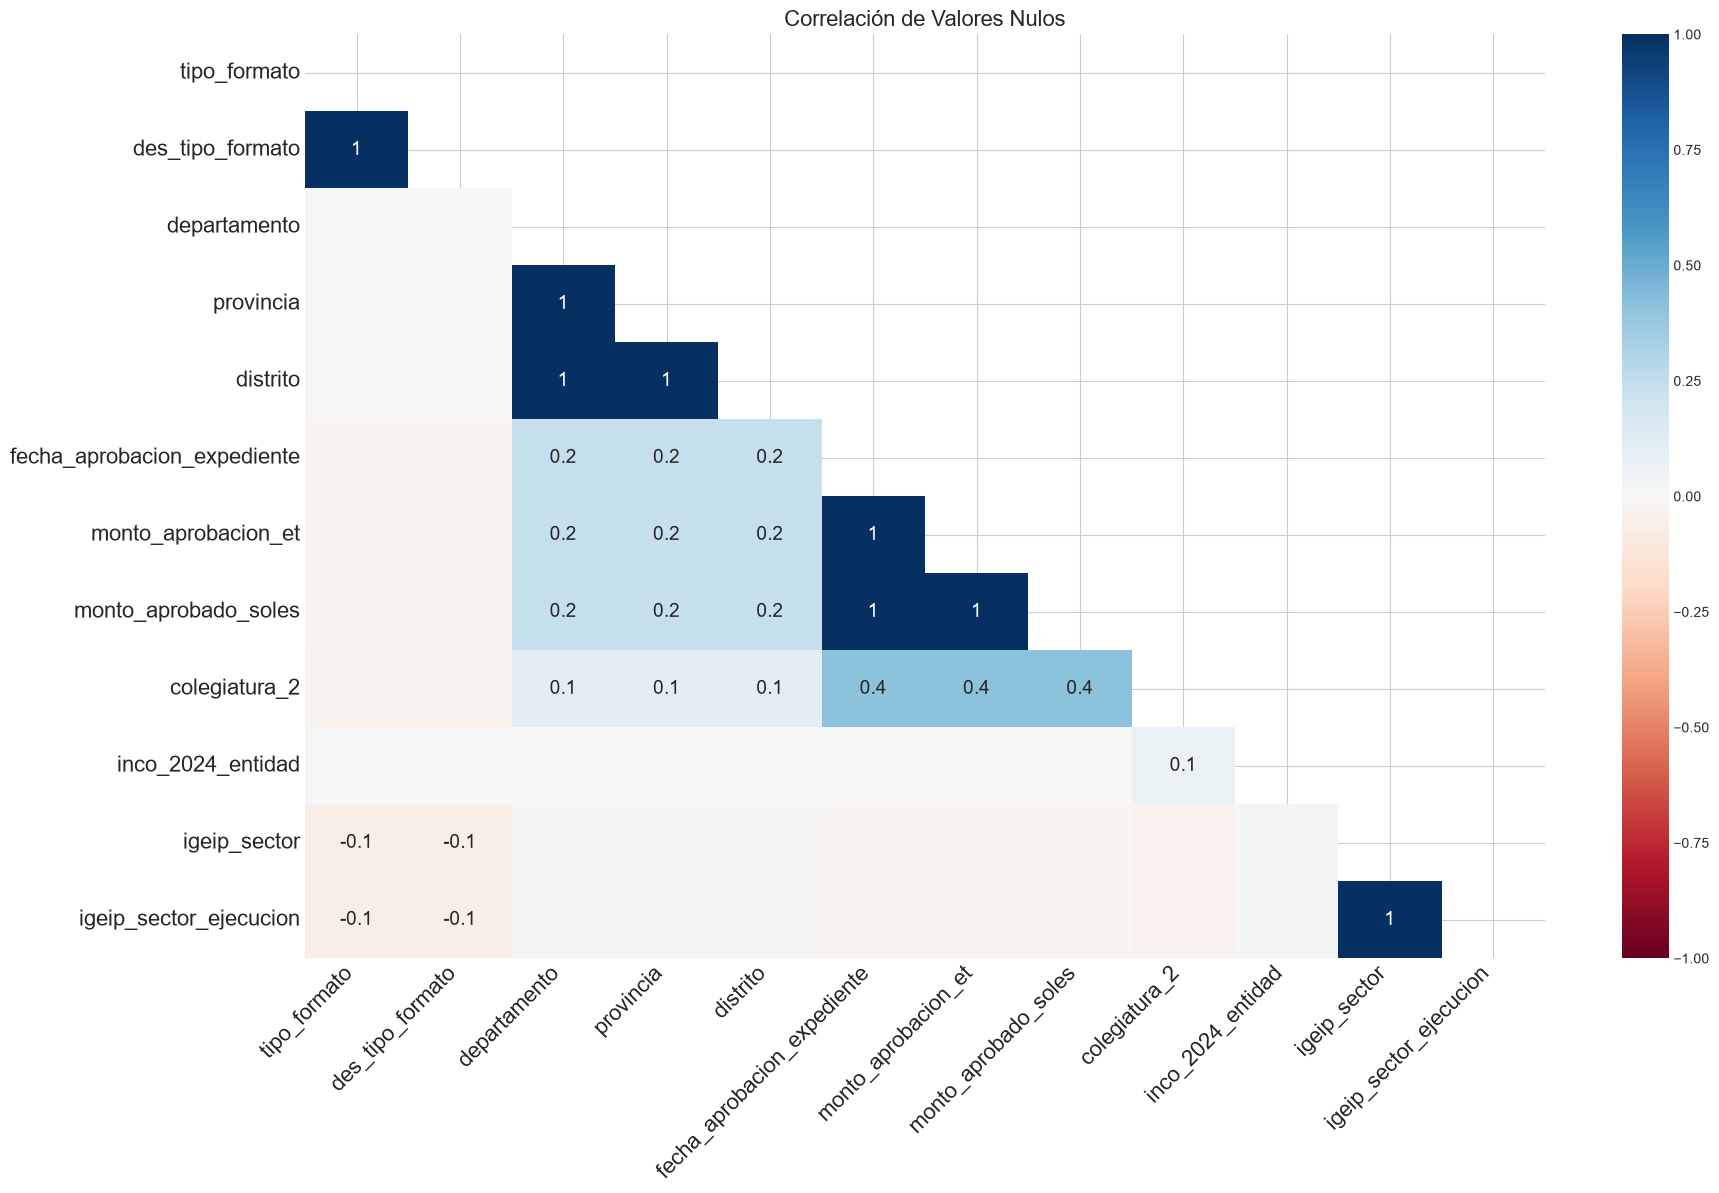

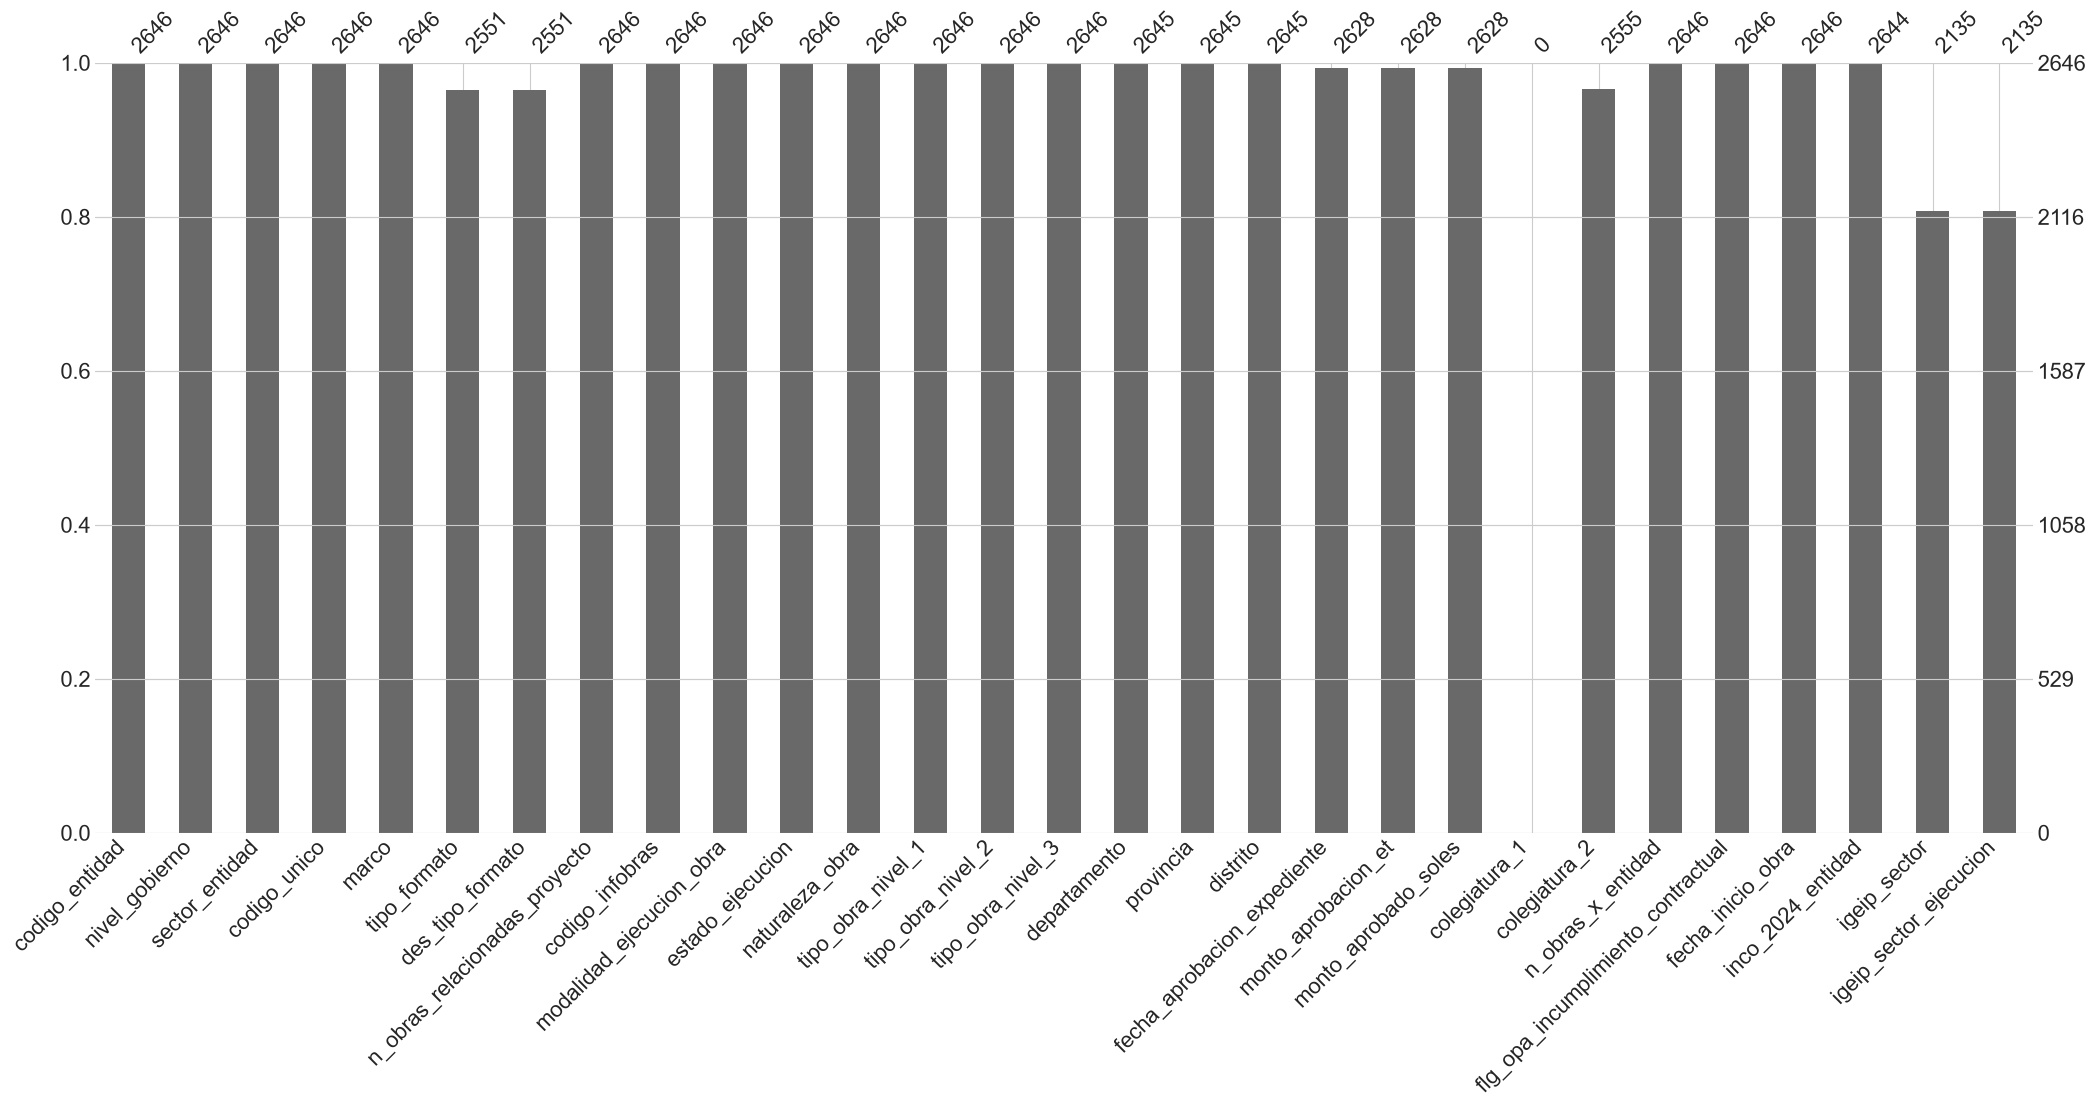

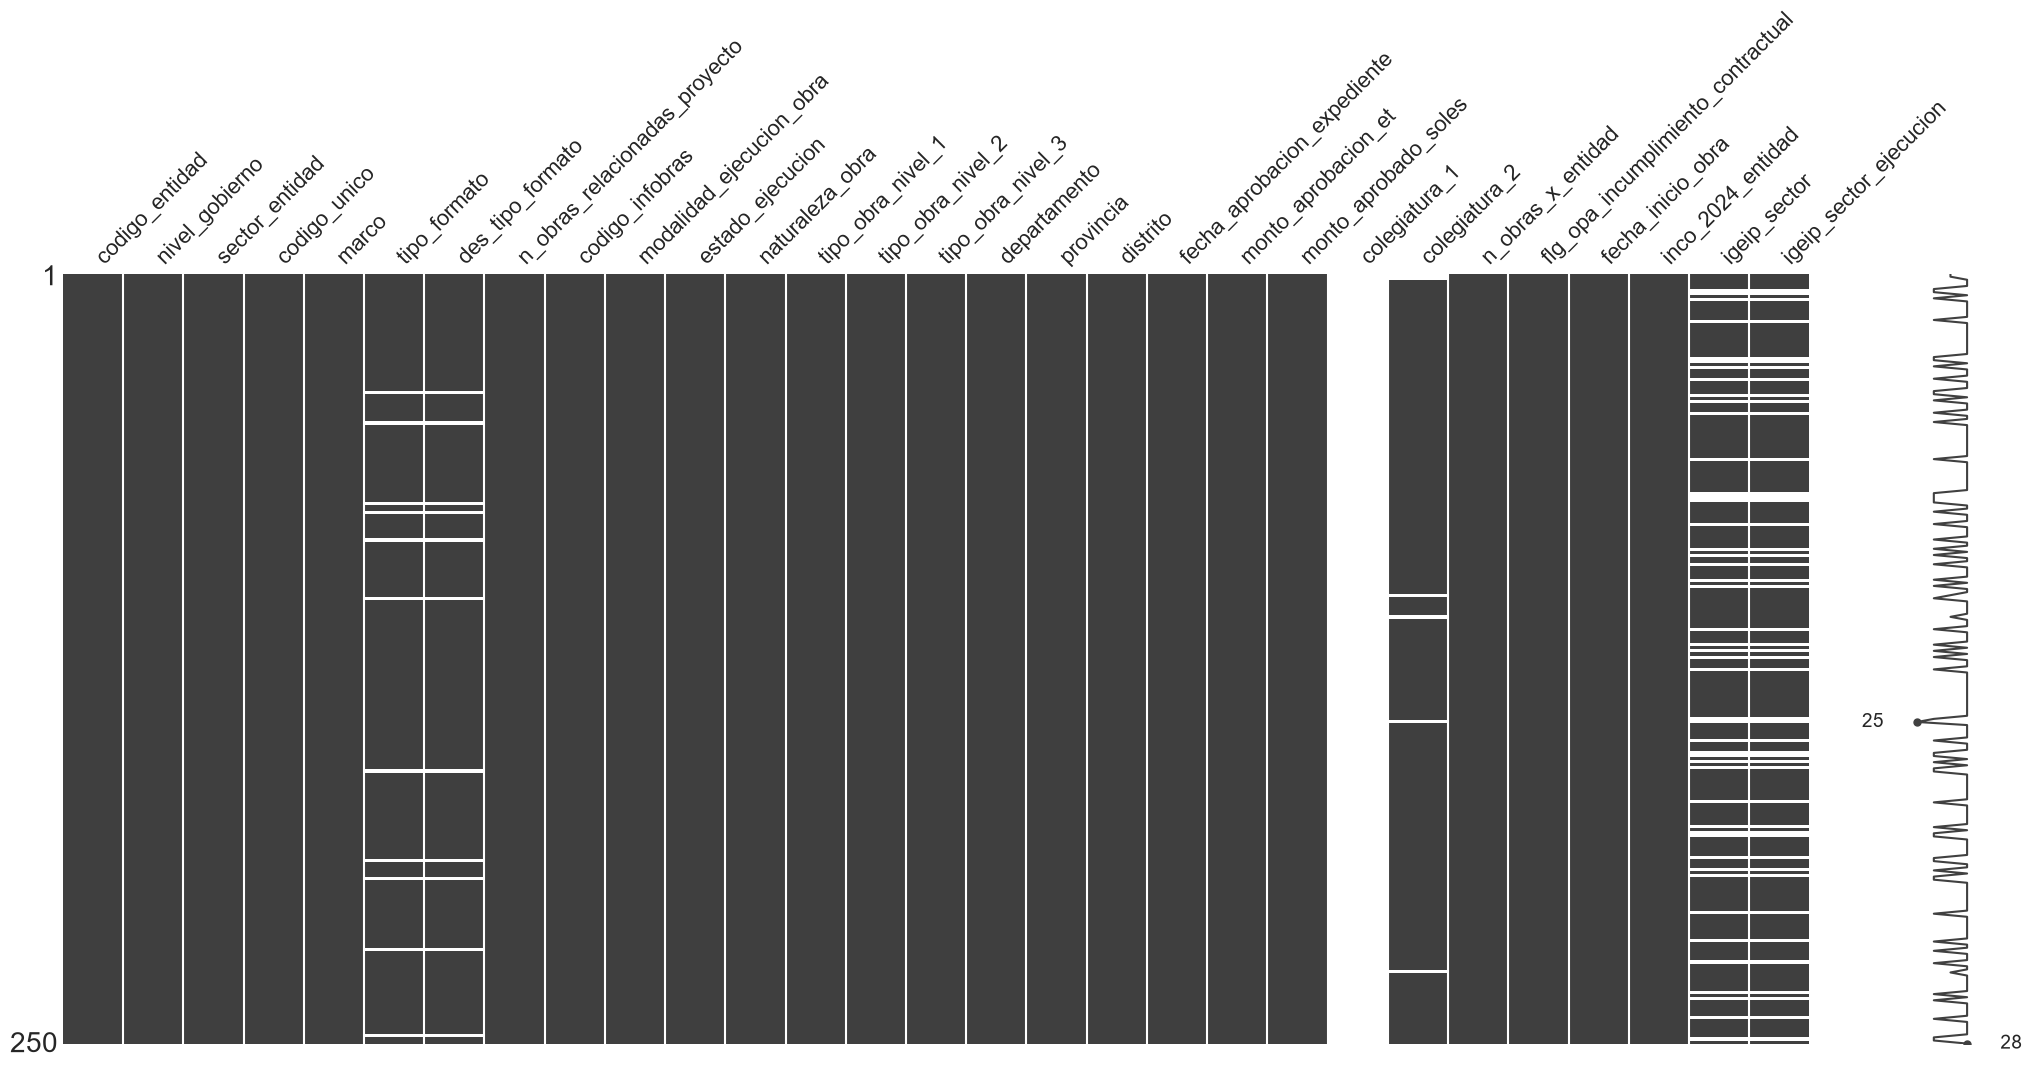

In [13]:
import missingno as msno
import matplotlib.pyplot as plt

# Matriz de calor: Muestra la correlación de nulidad entre columnas (-1 a 1)
# Un valor de 1 significa que si falta una variable, la otra siempre faltará también.
msno.heatmap(df_reducido)
plt.title("Correlación de Valores Nulos", fontsize=16)
plt.show()

# Gráfico de barras de completitud: Muestra visualmente qué tan llenas están las columnas
msno.bar(df_reducido)
plt.show()

msno.matrix(df_reducido.sample(250)) 
plt.show()

#### 3.1. Analisis del campo `monto_aprobado_soles`

In [15]:
df_reducido.loc[df_reducido['monto_aprobado_soles'].isnull()
                , ['monto_aprobado_soles', 'flg_opa_incumplimiento_contractual']]

,monto_aprobado_soles,flg_opa_incumplimiento_contractual
4005,NaN,0
13925,NaN,0
24326,NaN,0
26247,NaN,0
28603,NaN,0
41243,NaN,0
41817,NaN,0
46958,NaN,0
47206,NaN,0
48022,NaN,0


##### Eliminamos los valores nulos de `monto_aprobado_soles`

- Esto debido a que solo impacta en la clase mayoritaria `0`

In [16]:
df_invierte_nacional = df_reducido.dropna(subset=['monto_aprobado_soles'])

#### Analisis de otros campos con valores nulos

In [17]:
missing_report_2 = missing_values_report(df_invierte_nacional)
display(missing_report_2)

,missing_count,missing_percentage
colegiatura_1,2628,100.00
igeip_sector,509,19.37
igeip_sector_ejecucion,509,19.37
des_tipo_formato,95,3.61
tipo_formato,95,3.61
colegiatura_2,74,2.82
inco_2024_entidad,2,0.08


In [18]:
df_invierte_nacional[['colegiatura_2', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, normalize=True, sort=False)

colegiatura_2  flg_opa_incumplimiento_contractual
C I P          0                                     0.834094
C A P          0                                     0.055175
C I P          1                                     0.073440
C A P          1                                     0.001522
No aplica      0                                     0.006849
NaN            0                                     0.028158
R N A          0                                     0.000761
Name: proportion, dtype: float64

In [19]:
df_invierte_nacional[['des_tipo_formato', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, normalize=True, sort=False)

des_tipo_formato       flg_opa_incumplimiento_contractual
INVERSIONES IOARR      0                                     0.351218
NaN                    0                                     0.033105
INTERVENCIONES IRI     0                                     0.229452
PROYECTO DE INVERSION  0                                     0.311263
INTERVENCIONES IRI     1                                     0.039193
INVERSIONES IOARR      1                                     0.013318
PROYECTO DE INVERSION  1                                     0.019406
NaN                    1                                     0.003044
Name: proportion, dtype: float64

findfont: Failed to find font weight medium, now using 400.


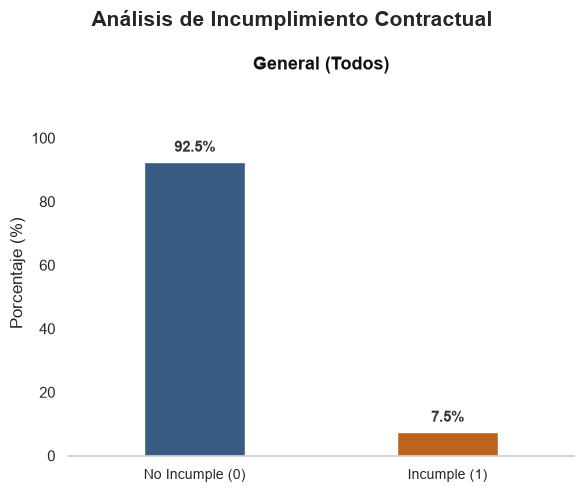

In [20]:
# --- 1. PREPARACIÓN DE DATOS ---
# Calculamos la distribución general
df_aux = df_invierte_nacional['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).reset_index()
df_aux.columns = ['Clase', 'Porcentaje']
df_aux['Porcentaje'] = df_aux['Porcentaje'] * 100  # Convertir a base 100

# --- 2. CONFIGURACIÓN DEL LIENZO (Un solo gráfico) ---
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6, 5))  # Dimensiones optimizadas para una figura única

# Paleta de colores (Azul para 0, Naranja para 1)
colors = {0: '#2b5c8f', 1: '#d95f02'}

# --- 3. GENERACIÓN DEL GRÁFICO ---
bars = sns.barplot(
    x='Clase', 
    y='Porcentaje', 
    data=df_aux, 
    palette=colors, 
    hue='Clase', 
    legend=False,
    width=0.4,  # Ancho estilizado para las dos barras
    ax=ax
)

# Añadimos las etiquetas de porcentaje sobre cada barra
for bar in bars.patches:
    height = bar.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.1f}%',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha='center', va='bottom', 
            fontsize=11, fontweight='bold', color='#333333'
        )
        
# Estética del gráfico (Limpieza visual)
ax.set_title('General (Todos)', fontsize=13, fontweight='bold', pad=15, color='#111111')
ax.set_xlabel('')
ax.set_ylabel('Porcentaje (%)', fontsize=12, fontweight='medium')

# Eliminar bordes innecesarios
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#cccccc')

# Ajustar etiquetas del eje X de forma segura
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)

# Ajustes globales
plt.ylim(0, 115)  # Espacio superior para las etiquetas
plt.suptitle('Análisis de Incumplimiento Contractual', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


In [21]:
df_invierte_nacional['flg_opa_incumplimiento_contractual'].value_counts()

flg_opa_incumplimiento_contractual
0    2431
1     197
Name: count, dtype: int64

### 4. Pre-tratamiento de outliers

#### 4.1. Funcion para analisis de outliers (Var numerica Vs Target Binario)

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analizar_outliers_monto_vs_target(
    df: pd.DataFrame,
    col_monto: str = "monto_aprobado_soles",
    col_target: str = "flg_opa_incumplimiento_contractual"
):
    data = df[[col_monto, col_target]].copy()

    # Asegurar numérico
    data[col_monto] = pd.to_numeric(data[col_monto], errors="coerce")

    # Eliminar nulos para el análisis
    data = data.dropna(subset=[col_monto, col_target])

    print("=== RESUMEN GENERAL ===")
    print(data[col_monto].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

    print("\n=== RESUMEN POR TARGET ===")
    resumen_target = data.groupby(col_target)[col_monto].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    )
    print(resumen_target)

    # IQR general
    q1 = data[col_monto].quantile(0.25)
    q3 = data[col_monto].quantile(0.75)
    iqr = q3 - q1

    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    data["es_outlier_iqr"] = (
        (data[col_monto] < limite_inf) |
        (data[col_monto] > limite_sup)
    )

    print("\n=== OUTLIERS POR IQR ===")
    print(f"Límite inferior: {limite_inf:,.2f}")
    print(f"Límite superior: {limite_sup:,.2f}")
    print(data["es_outlier_iqr"].value_counts())

    print("\n=== OUTLIERS POR TARGET ===")
    print(pd.crosstab(data[col_target], data["es_outlier_iqr"], normalize="index") * 100)

    # Gráficos
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.boxplot(data=data, x=col_target, y=col_monto, ax=axes[0])
    axes[0].set_title("Monto aprobado por target")
    axes[0].set_xlabel(col_target)
    axes[0].set_ylabel(col_monto)

    sns.boxplot(data=data, x=col_target, y=np.log1p(data[col_monto]), ax=axes[1])
    axes[1].set_title("Log(1 + monto) por target")
    axes[1].set_xlabel(col_target)
    axes[1].set_ylabel(f"log1p({col_monto})")

    sns.histplot(
        data=data,
        x=np.log1p(data[col_monto]),
        hue=col_target,
        kde=True,
        bins=50,
        ax=axes[2]
    )
    axes[2].set_title("Distribución logarítmica por target")
    axes[2].set_xlabel(f"log1p({col_monto})")

    plt.tight_layout()
    plt.show()

    return data, resumen_target

#### 4.2. Analisis de Outliers

monto_aprobado_soles

=== RESUMEN GENERAL ===
count    2.628000e+03
mean     9.211674e+06
std      3.605973e+07
min      0.000000e+00
1%       1.362962e+04
5%       7.725712e+04
25%      4.604977e+05
50%      1.454460e+06
75%      5.682044e+06
95%      3.751894e+07
99%      1.050263e+08
max      6.854283e+08
Name: monto_aprobado_soles, dtype: float64

=== RESUMEN POR TARGET ===
                                     count          mean           std  min  \
flg_opa_incumplimiento_contractual                                            
0                                   2431.0  9.167923e+06  3.713764e+07  0.0   
1                                    197.0  9.751567e+06  1.812244e+07  0.0   

                                          1%          5%          25%  \
flg_opa_incumplimiento_contractual                                      
0                                   14479.93   76061.685   417799.825   
1                                       0.00  361200.482  1939611.000   

                               

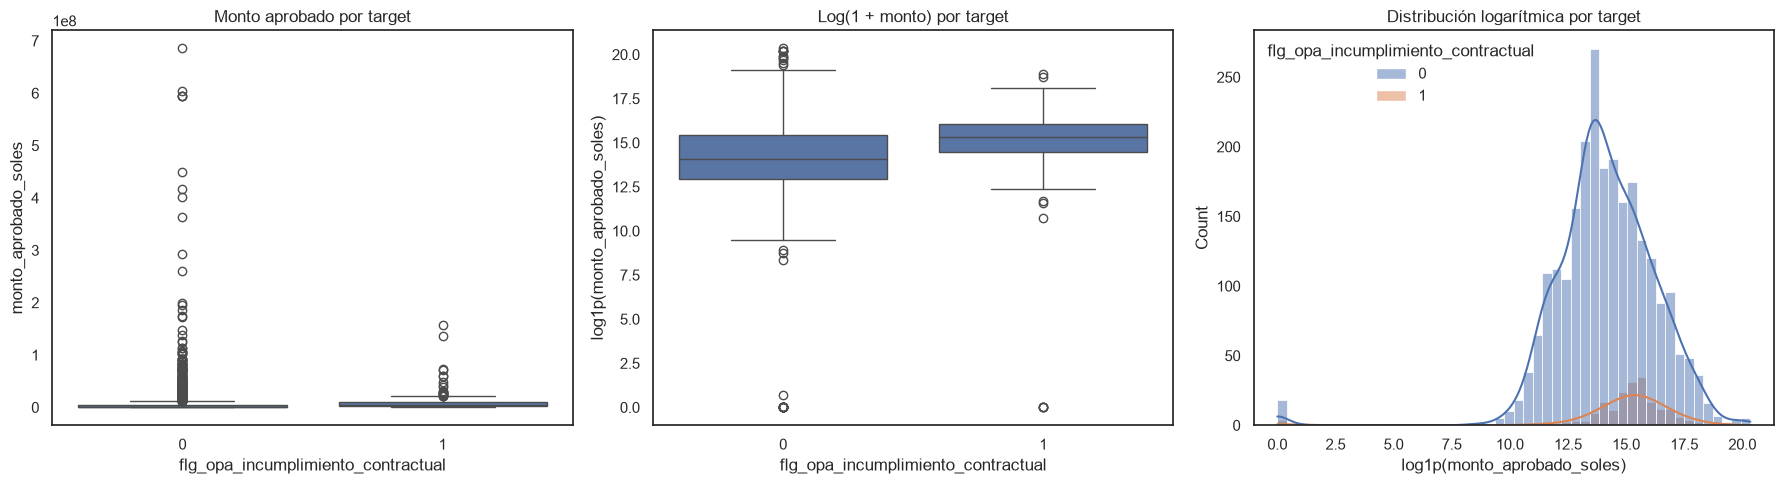

In [23]:
data_outliers, resumen_monto_target = analizar_outliers_monto_vs_target(df_invierte_nacional)

#### 4.3. Transformaciones para outliers

1. Tratar registros con monto_aprobado_soles = 0, reemplazar por el campo monto_aprobado_et
2. Eliminar registro con monto_aprobado_soles = 1 (un caso)
2. Transformación logaritmica log(monto_aprobado_soles)
3. Winsorización de la variable monto_aprobado_soles

##### Analisis y corrección de errores de registros (puntos 1 y 2)

In [329]:
df_invierte_nacional.loc[df_invierte_nacional['monto_aprobado_soles'] ==0, ['monto_aprobado_soles', 'monto_aprobacion_et']]

,monto_aprobado_soles,monto_aprobacion_et
4003,0.0,3.002065e+07
7544,0.0,3.096118e+06
9828,0.0,6.783442e+06
16074,0.0,2.614075e+06
24538,0.0,8.982506e+06
25471,0.0,1.336585e+08
25472,0.0,6.539825e+07
29669,0.0,2.782901e+07
30586,0.0,8.151859e+05
30648,0.0,9.370533e+06


In [330]:
df_invierte_nacional.loc[df_invierte_nacional["monto_aprobado_soles"] == 1, ['monto_aprobado_soles', 'monto_aprobacion_et', 'flg_opa_incumplimiento_contractual']]

,monto_aprobado_soles,monto_aprobacion_et,flg_opa_incumplimiento_contractual
49855,1.0,1.0,0


In [331]:
# Si monto_aprobado_soles == 0, reemplazar por monto_aprobacion_et
df_invierte_nacional.loc[df_invierte_nacional["monto_aprobado_soles"] == 0, "monto_aprobado_soles"] = df_invierte_nacional.loc[
    df_invierte_nacional["monto_aprobado_soles"] == 0, "monto_aprobacion_et"]

In [332]:
# Si monto_aprobado_soles == 1, eliminar el registro
df_invierte_nacional = df_invierte_nacional[df_invierte_nacional["monto_aprobado_soles"] != 1].copy()

=== RESUMEN GENERAL ===
count    2.627000e+03
mean     9.387951e+06
std      3.619776e+07
min      4.316080e+03
1%       3.320584e+04
5%       8.551156e+04
25%      5.007165e+05
50%      1.506341e+06
75%      5.821013e+06
95%      3.889671e+07
99%      1.059563e+08
max      6.854283e+08
Name: monto_aprobado_soles, dtype: float64

=== RESUMEN POR TARGET ===
                                     count          mean           std  \
flg_opa_incumplimiento_contractual                                       
0                                   2430.0  9.352824e+06  3.728421e+07   
1                                    197.0  9.821241e+06  1.809381e+07   

                                         min           1%          5%  \
flg_opa_incumplimiento_contractual                                      
0                                    4316.08   31994.0074   81958.690   
1                                   46059.73  118648.1884  635633.876   

                                           25%     

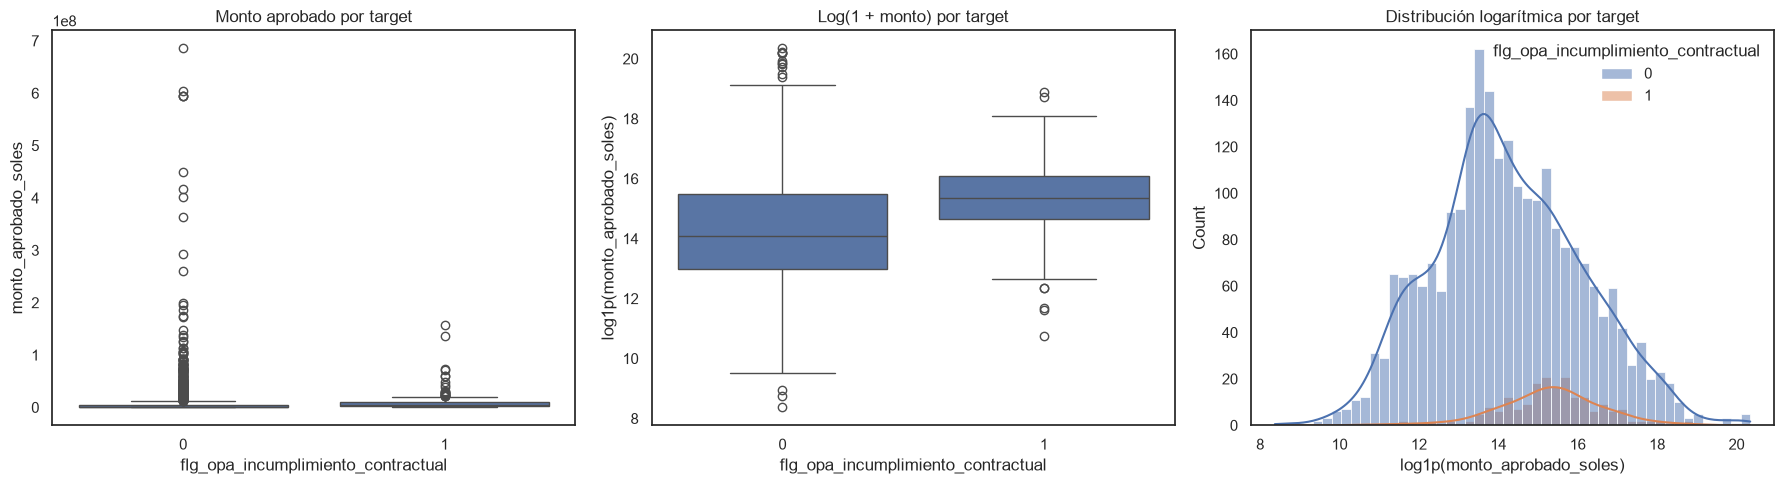

In [333]:
data_outliers_2, resumen_monto_target_2 = analizar_outliers_monto_vs_target(df_invierte_nacional)

##### Nuevas columnas Log y Winzorizada de monto_aprobado_soles

In [24]:
df_invierte_nacional["monto_aprobado_soles_log"] = np.log1p(df_invierte_nacional["monto_aprobado_soles"])

In [25]:
p99 = df_invierte_nacional["monto_aprobado_soles"].quantile(0.99)

df_invierte_nacional["monto_aprobado_soles_winsor_log"] = np.log1p(
    df_invierte_nacional["monto_aprobado_soles"].clip(upper=p99)
)

In [26]:
df_invierte_nacional.groupby('flg_opa_incumplimiento_contractual')[
    ['monto_aprobado_soles_log', 'monto_aprobado_soles_winsor_log']
].describe()

monto_aprobado_soles_log             \
                                                      count       mean   
flg_opa_incumplimiento_contractual                                       
0                                                    2431.0  14.111181   
1                                                     197.0  15.012977   

                                                                         \
                                         std  min        25%        50%   
flg_opa_incumplimiento_contractual                                        
0                                   2.240762  0.0  12.942760  14.057409   
1                                   2.511183  0.0  14.477999  15.332460   

                                                          \
                                          75%        max   
flg_opa_incumplimiento_contractual                         
0                                   15.454257  20.345554   
1                                   16.086811  18.874925   

                                   monto_aprobado_soles_winsor_log             \
                                                             count       mean   
flg_opa_incumplimiento_contractual                                              
0                                                           2431.0  14.102879   
1                                                            197.0  15.009607   

                                                                         \
                                         std  min        25%        50%   
flg_opa_incumplimiento_contractual                                        
0                                   2.222060  0.0  12.942760  14.057409   
1                                   2.506279  0.0  14.477999  15.332460   

                                                          
                                          75%        max  
flg_opa_incumplimiento_contractual                        
0                                   15.454257  18.469721  
1                                   16.086811  18.469721

### Separación caracteristicas por tipo de dato

In [27]:
# =============================================================================
# 2.4 Listar columnas disponibles por tipo
# =============================================================================

def clasificar_columnas_por_tipo(dataframe):
    """Clasifica columnas según su tipo de dato."""
    cols_numericas = dataframe.select_dtypes(include=[np.number]).columns.tolist()
    cols_categoricas = dataframe.select_dtypes(include=['object', 'category']).columns.tolist()
    cols_datetime = dataframe.select_dtypes(include=['datetime64']).columns.tolist()
    cols_bool = dataframe.select_dtypes(include=['bool']).columns.tolist()
    
    return {
        'numericas': cols_numericas,
        'categoricas': cols_categoricas,
        'datetime': cols_datetime,
        'booleanas': cols_bool
    }

tipos_columnas = clasificar_columnas_por_tipo(df_invierte_nacional)

print("Clasificación de Columnas por Tipo")
print("=" * 60)
for tipo, columnas in tipos_columnas.items():
    print(f"\n{tipo.upper()} ({len(columnas)} columnas):")
    for col in columnas:
        print(f"  - {col}")

Clasificación de Columnas por Tipo

NUMERICAS (15 columnas):
  - codigo_entidad
  - codigo_unico
  - tipo_formato
  - n_obras_relacionadas_proyecto
  - codigo_infobras
  - monto_aprobacion_et
  - monto_aprobado_soles
  - colegiatura_1
  - n_obras_x_entidad
  - flg_opa_incumplimiento_contractual
  - inco_2024_entidad
  - igeip_sector
  - igeip_sector_ejecucion
  - monto_aprobado_soles_log
  - monto_aprobado_soles_winsor_log

CATEGORICAS (16 columnas):
  - nivel_gobierno
  - sector_entidad
  - marco
  - des_tipo_formato
  - modalidad_ejecucion_obra
  - estado_ejecucion
  - naturaleza_obra
  - tipo_obra_nivel_1
  - tipo_obra_nivel_2
  - tipo_obra_nivel_3
  - departamento
  - provincia
  - distrito
  - fecha_aprobacion_expediente
  - colegiatura_2
  - fecha_inicio_obra

DATETIME (0 columnas):

BOOLEANAS (0 columnas):


C:\Users\yanfr\AppData\Local\Temp\ipykernel_58772\1246815510.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_categoricas = dataframe.select_dtypes(include=['object', 'category']).columns.tolist()


In [28]:
df_invierte_nacional[['tasa_paralizacion_entidad']].describe()

KeyError: "None of [Index(['tasa_paralizacion_entidad'], dtype='str')] are in the [columns]"

In [29]:
df_invierte_nacional[['naturaleza_obra', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, sort=False)

naturaleza_obra        flg_opa_incumplimiento_contractual
Mejoramiento           0                                     553
Remodelación           0                                     181
Rehabilitación         0                                     413
Ampliación             0                                     158
Construcción/Creación  0                                     493
Instalación            0                                     202
Rehabilitación         1                                      83
Recuperación           0                                      22
Renovación             0                                     125
Reparación             0                                     110
Reconstrucción         1                                      20
                       0                                     147
Remodelación           1                                       8
Recuperación           1                                       2
Mejoramiento           1        

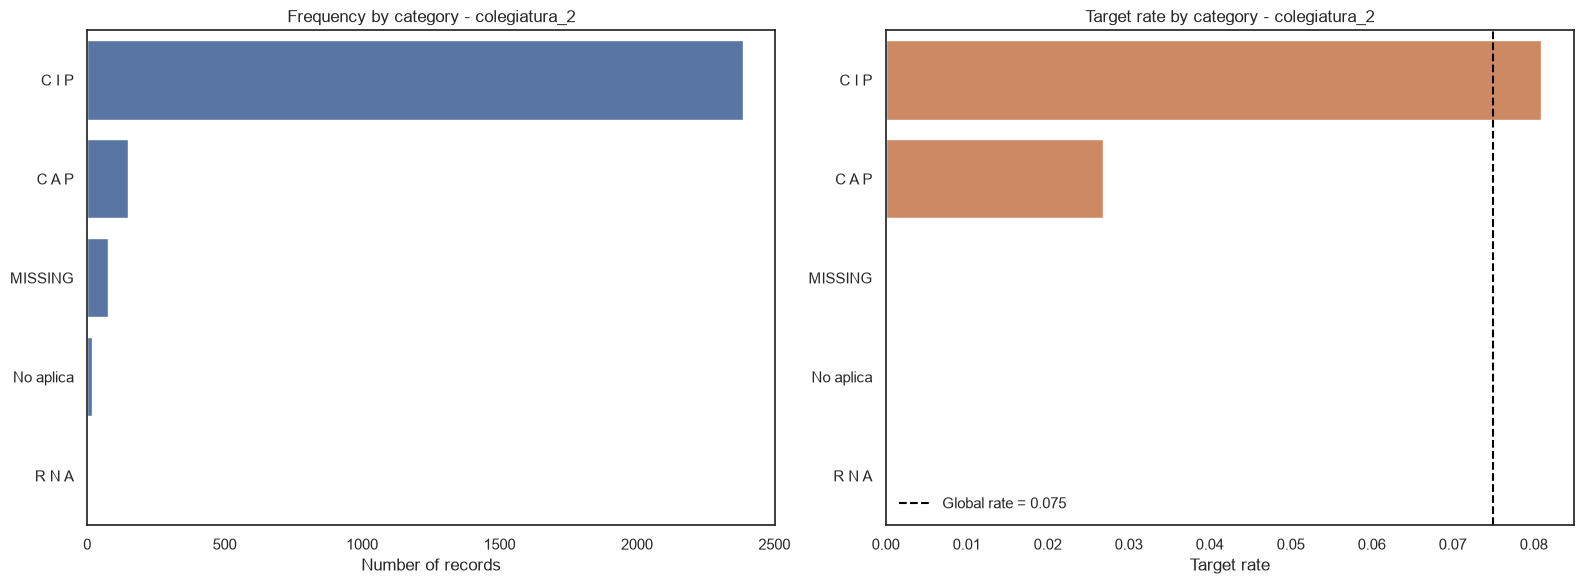

,colegiatura_2,count,target_count,target_rate,sample_percentage,lift_vs_global,is_rare_category
1,C I P,2385,193,0.080922,0.907534,1.079513,False
0,C A P,149,4,0.026846,0.056697,0.358124,False
2,MISSING,74,0,0.000000,0.028158,0.000000,False
3,No aplica,18,0,0.000000,0.006849,0.000000,True
4,R N A,2,0,0.000000,0.000761,0.000000,True


In [35]:
from src.eda import analyze_categorical_vs_target

summary = analyze_categorical_vs_target(
    data=df_invierte_nacional,
    categorical_column="colegiatura_2",
    target_column="flg_opa_incumplimiento_contractual",
    min_count=20,
    top_n=20,
)

display(summary)

## Ingenieria de caracteristicas

### 1. Separar X e y

In [341]:
from sklearn.model_selection import train_test_split

In [342]:
TARGET = 'flg_opa_incumplimiento_contractual'

df_model = df_invierte_nacional.copy()

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET].astype(int)

### 2. Train, Test split

Separamos Train, Test dataset para trabajar la ingenieria de caracteristicas sobre X_train y evitar el data leakage

In [343]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [344]:
y_train.value_counts(normalize=True)

flg_opa_incumplimiento_contractual
0    0.924798
1    0.075202
Name: proportion, dtype: float64

In [345]:
missing_report_X_train = missing_values_report(X_train)

In [346]:
missing_report_X_train

,missing_count,missing_percentage
colegiatura_1,2101,100.00
tipo_formato,82,3.90
des_tipo_formato,82,3.90
colegiatura_2,58,2.76


### 3. Definir grupos de columnas

In [347]:
# Columnas que requieren transformación logaritmica y winsorizacion
amount_log_cols = [
    "monto_aprobado_soles"
]
# Columnas numericas que requieren estandarización
numeric_standard_cols = [
    #"n_obras_relacionadas_proyecto",
    #"tasa_paralizacion_entidad", # Se debe calcular en Train para evitar el data leakage
    "n_obras_x_entidad",
    #"monto_aprobado_soles_promedio_entidad", # Se debe calcular en Train para evitar el data leakage
    #"tasa_paralizacion_departamento", # Se debe calcular en Train para evitar el data leakage
    #"tasa_paralizacion_tipo_obra_nivel_1", # Se debe calcular en Train para evitar el data leakage
    ### Calculados
    'monto_aprobado_soles_log'
]

categorical_cols = [
    #"nivel_gobierno", #"GOBIERNO NACIONAL"
    "sector_entidad",
    #"marco", # 'INVIERTE'
    "tipo_formato",
    #"des_tipo_formato", # tipo_formato
    #"modalidad_ejecucion_obra", # Un unico valor para el dataset: 'Contrata'
    #"estado_ejecucion",
    "naturaleza_obra",
    "tipo_obra_nivel_1",
    #"tipo_obra_nivel_2",
    #"tipo_obra_nivel_3",
    "departamento",
    #"provincia", # Muy granular
    #"distrito", # Muy granular
    #"colegiatura_2", # No es un buen discriminador
]

### Imputación de valores nulos

In [348]:
from sklearn.impute import SimpleImputer

cat_missing_cols = [
    'tipo_formato',
]

num_imputer = SimpleImputer(strategy='median')

X_train_num_imp = pd.DataFrame(
    num_imputer.fit_transform(X_train[cat_missing_cols]),
    columns=cat_missing_cols,
    index=X_train.index
)

X_test_num_imp = pd.DataFrame(
    num_imputer.transform(X_test[cat_missing_cols]),
    columns=cat_missing_cols,
    index=X_test.index
)

### Calculo de ratios de paralizacion
- naturaleza_obra
- tipo_obra_nivel_1
- departamento


In [349]:
def fit_target_rate(X_train, y_train, col, smoothing=20):
    temp = pd.DataFrame({
        col: X_train[col].astype("object").fillna("MISSING"),
        "target": y_train
    })

    global_rate = temp["target"].mean()

    stats = (
        temp
        .groupby(col)["target"]
        .agg(["mean", "count"])
    )

    stats["rate_smooth"] = (
        (stats["mean"] * stats["count"] + global_rate * smoothing)
        / (stats["count"] + smoothing)
    )

    mapping = stats["rate_smooth"].to_dict()

    return mapping, global_rate


def transform_target_rate(X, col, mapping, global_rate):
    return (
        X[col]
        .astype("object")
        .fillna("MISSING")
        .map(mapping)
        .fillna(global_rate)
        .astype(float)
    )

In [350]:
mapping_depto, global_rate = fit_target_rate(
    X_train,
    y_train,
    col="departamento",
    smoothing=20
)

X_train_rate = pd.DataFrame(index=X_train.index)
X_test_rate = pd.DataFrame(index=X_test.index)

X_train_rate["departamento_target_rate"] = transform_target_rate(
    X_train,
    "departamento",
    mapping_depto,
    global_rate
)

X_test_rate["departamento_target_rate"] = transform_target_rate(
    X_test,
    "departamento",
    mapping_depto,
    global_rate
)

In [351]:
global_rate


np.float64(0.0752022846263684)

In [352]:
fit_target_rate(X_train=X_train, y_train=y_train, col='departamento', smoothing=20)

({'AMAZONAS': 0.033371863738355885,
  'ANCASH': 0.13969249268229705,
  'APURIMAC': 0.05005779560753383,
  'AREQUIPA': 0.0862533987646824,
  'AYACUCHO': 0.04317320159529945,
  'CAJAMARCA': 0.05733380929716009,
  'CUSCO': 0.07504045692527368,
  'HUANCAVELICA': 0.0956477307724613,
  'HUANUCO': 0.025814904046673897,
  'ICA': 0.09328891004283675,
  'JUNIN': 0.11733389743860949,
  'LA LIBERTAD': 0.12190028557829605,
  'LAMBAYEQUE': 0.06359360756379126,
  'LIMA': 0.06448150628231338,
  'LORETO': 0.036290517283005336,
  'MADRE DE DIOS': 0.12800106261691555,
  'MOQUEGUA': 0.08831462142210526,
  'NO APLICA': 0.05186364456990924,
  'P C DEL CALLAO': 0.11260114231318422,
  'PASCO': 0.03958014980335179,
  'PIURA': 0.05683131718353041,
  'PUNO': 0.05118233741508373,
  'SAN MARTIN': 0.02387374115122806,
  'TACNA': 0.03008091385054736,
  'TUMBES': 0.14562083155097935,
  'UCAYALI': 0.036824201360696585},
 np.float64(0.0752022846263684))

In [353]:
X_train_rate.head(20) 

,departamento_target_rate
2777,0.056831
38525,0.033372
54462,0.051182
46735,0.056831
14942,0.064482
67537,0.056831
3744,0.145621
25369,0.112601
8703,0.064482
26680,0.023874


In [354]:
pd.DataFrame({
    "departamento": mapping_depto.keys(),
    "target_rate_smooth": mapping_depto.values()
}).sort_values("target_rate_smooth", ascending=False)

,departamento,target_rate_smooth
24,TUMBES,0.145621
1,ANCASH,0.139692
15,MADRE DE DIOS,0.128001
11,LA LIBERTAD,0.121900
10,JUNIN,0.117334
18,P C DEL CALLAO,0.112601
7,HUANCAVELICA,0.095648
9,ICA,0.093289
16,MOQUEGUA,0.088315
3,AREQUIPA,0.086253


### 4. Definir transformadores por grupo

In [355]:
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [356]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin


class WinsorLogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, upper_quantile=0.99):
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X = self._to_dataframe(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.upper_bounds_ = X.quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X = self._to_dataframe(X).copy()
        X = X.clip(upper=self.upper_bounds_, axis=1)
        X = np.log1p(X)

        return pd.DataFrame(
            X,
            columns=self.feature_names_in_,
            index=X.index
        )

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_

        return np.array(
            [f"{col}_winsor_log" for col in input_features],
            dtype=object
        )

    def _to_dataframe(self, X):
        if isinstance(X, pd.DataFrame):
            return X

        return pd.DataFrame(X)

In [357]:
amount_log_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

In [358]:
preprocessor = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline, numeric_standard_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

In [359]:
X_train_processed = preprocessor.fit_transform(X_train, y_train)
X_test_processed = preprocessor.transform(X_test)

In [360]:
from scipy import sparse
import joblib

sparse.save_npz("X_train_processed.npz", X_train_processed)
sparse.save_npz("X_test_processed.npz", X_test_processed)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

joblib.dump(preprocessor, "preprocessor.joblib")

['preprocessor.joblib']

In [361]:
feature_names = preprocessor.get_feature_names_out()

pd.Series(feature_names).to_csv(
    "feature_names.csv",
    index=False
)

In [362]:
X_test_df = pd.DataFrame(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    columns=feature_names
)

X_test_df.to_csv("X_test_processed.csv", index=False)

### 5. Definir Pipeline (preprocesamiento + predictor)

In [363]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="saga",
    penalty="l2",
    random_state=42
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

### 7. Evaluación (modelo base)

In [364]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [365]:
# 1. Entrena el pipeline con tus datos de entrenamiento
model_pipeline.fit(X_train, y_train)

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['codigo_entidad','nivel_gobierno','sector_entidad',..., 'fecha_inicio_obra','monto_aprobado_soles_log', 'monto_aprobado_soles_winsor_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('amount_log', ...), ('numeric_standard', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-spe

In [366]:
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

In [367]:
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

ROC AUC: 0.7391670615489918
PR AUC: 0.311434976427537

Matriz de confusión:
[[345 142]
 [ 15  24]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      0.71      0.81       487
           1       0.14      0.62      0.23        39

    accuracy                           0.70       526
   macro avg       0.55      0.66      0.52       526
weighted avg       0.90      0.70      0.77       526



**Metricas globales (test M2)**

|         |   valor |
|:--------|--------:|
| ROC AUC |  0.7392 |
| PR AUC  |  0.3114 |

**Reporte de clasificacion (test M2)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.958 |    0.708 |      0.815 |   487     |
| 1            |       0.145 |    0.615 |      0.234 |    39     |
| accuracy     |       0.702 |    0.702 |      0.702 |     0.702 |
| macro avg    |       0.551 |    0.662 |      0.524 |   526     |
| weighted avg |       0.898 |    0.702 |      0.772 |   526     |

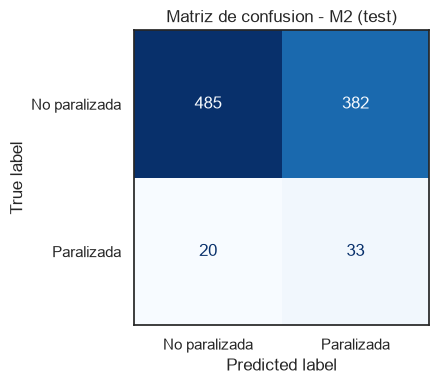

In [368]:
from sklearn.metrics import ConfusionMatrixDisplay

metrics_m2 = pd.Series({
    "ROC AUC": roc_auc_score(y_test, y_proba),
    "PR AUC": average_precision_score(y_test, y_proba),
}, name="valor")
display(Markdown("**Metricas globales (test M2)**"))
display(Markdown(metrics_m2.to_frame().round(4).to_markdown()))

report_m2 = classification_report(y_test, y_pred, output_dict=True)
display(Markdown("**Reporte de clasificacion (test M2)**"))
display(Markdown(pd.DataFrame(report_m2).T.round(3).to_markdown()))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_m2, y_pred_m2,
    display_labels=["No paralizada", "Paralizada"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Matriz de confusion - M2 (test)")
plt.tight_layout()
plt.show()


## Aplicacion de modelo de clasificación

- `M2`: Realizar un particionamiento del dataset usando la `fecha_inicio_obra` debido a la naturaleza temporal del fenomeno (se usa la historia de ejecuciones de proyectos para estimar el riesgo de paralización de obras futuras)
- `M3`: Realizar `time series cross validation split` para mejorar el sobre ajuste y fuga de datos (data leakage) en los conjuntos de train, val. y usar modelo de regresión logistica tradicional
- `M4`: GLM con distribucion polinomial y probit link function
- `M5`: GLM con distribucion binomial y c-loglog link function
- `M6`: GAM and logictic regresion
- `M7`: GAM and logistic regresion with c-loglog link function
- `M8`: Benchmark ML model random forest

### M2: Particion temporal (train, test) y modelo de regresión logista tradicional

In [369]:
DATE_COL = "fecha_inicio_obra"
TARGET = "flg_opa_incumplimiento_contractual"

df_m2 = df_invierte_nacional.copy()

In [370]:
df_m2 = df_m2.drop(columns=['tasa_paralizacion_tipo_obra_nivel_1', 'tasa_paralizacion_departamento', 'tasa_paralizacion_entidad'])

In [371]:
df_m2[DATE_COL] = pd.to_datetime(df_model[DATE_COL], errors="coerce")

In [372]:
df_m2 = df_m2.dropna(subset=[DATE_COL, TARGET])


In [373]:
df_m2 = df_m2.sort_values(DATE_COL).reset_index(drop=True)

In [374]:
split_idx = int(len(df_m2) * 0.65)

In [375]:
df_train_m2 = df_m2.iloc[:split_idx].copy()
df_test_m2 = df_m2.iloc[split_idx:].copy()

In [376]:
df_train_m2['fecha_inicio_obra'].describe()

count                   1707
mean     2020-08-14 11:19:55
min      2010-12-18 00:00:00
25%      2019-08-28 00:00:00
50%      2020-10-06 00:00:00
75%      2021-11-24 00:00:00
max      2023-01-11 00:00:00
Name: fecha_inicio_obra, dtype: object

In [377]:
df_test_m2['fecha_inicio_obra'].describe()

count                    920
mean     2024-04-29 03:00:00
min      2023-01-11 00:00:00
25%      2023-09-27 00:00:00
50%      2024-02-15 00:00:00
75%      2024-11-28 00:00:00
max      2025-12-20 00:00:00
Name: fecha_inicio_obra, dtype: object

In [378]:
display(Markdown(df_train_m2['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).to_markdown()))

|   flg_opa_incumplimiento_contractual |   proportion |
|-------------------------------------:|-------------:|
|                                    0 |    0.915641  |
|                                    1 |    0.0843585 |

In [379]:
display(Markdown(df_test_m2['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).to_markdown()))

|   flg_opa_incumplimiento_contractual |   proportion |
|-------------------------------------:|-------------:|
|                                    0 |    0.942391  |
|                                    1 |    0.0576087 |

#### Tasa de paralizacion por atributo (calculada sobre train para evitar data leakage)

In [380]:
def calcular_mapas_tasa_paralizacion(df_train, columnas, target_col=TARGET, smoothing=20):
    """Ajusta, usando solo el conjunto de entrenamiento, la tasa de paralizacion
    (media del target) por cada valor de las columnas categoricas indicadas.
    Aplica smoothing bayesiano hacia la tasa global para categorias con pocas observaciones.
    """
    tasa_global = df_train[target_col].mean()

    mapas = {}
    for col in columnas:
        stats = df_train.groupby(col)[target_col].agg(["mean", "count"])
        stats["rate_smooth"] = (
            (stats["mean"] * stats["count"] + tasa_global * smoothing)
            / (stats["count"] + smoothing)
        )
        mapas[col] = stats["rate_smooth"].to_dict()

    return mapas, tasa_global


def aplicar_tasa_paralizacion(df, columnas, mapas, tasa_global):
    """Agrega al dataframe las columnas tasa_paralizacion_{columna}, usando los mapas
    previamente ajustados sobre train. Los valores no vistos en train se imputan con la tasa global.
    """
    df = df.copy()
    for col in columnas:
        df[f"tasa_paralizacion_{col}"] = df[col].map(mapas[col]).fillna(tasa_global)
    return df


In [483]:
columnas_tasa_paralizacion = ["codigo_entidad", "tipo_obra_nivel_1", 'departamento', 'provincia', 'sector_entidad']

mapas_tasa_paralizacion, tasa_paralizacion_global = calcular_mapas_tasa_paralizacion(
    df_train_m2, columnas_tasa_paralizacion, target_col=TARGET, smoothing=20
)

df_train_m2 = aplicar_tasa_paralizacion(df_train_m2, columnas_tasa_paralizacion, mapas_tasa_paralizacion, tasa_paralizacion_global)
df_test_m2 = aplicar_tasa_paralizacion(df_test_m2, columnas_tasa_paralizacion, mapas_tasa_paralizacion, tasa_paralizacion_global)


In [484]:
df_train_m2[[f"tasa_paralizacion_{c}" for c in columnas_tasa_paralizacion]].describe()

,tasa_paralizacion_codigo_entidad,tasa_paralizacion_tipo_obra_nivel_1,tasa_paralizacion_departamento,tasa_paralizacion_provincia,tasa_paralizacion_sector_entidad
count,1707.000000,1707.000000,1707.000000,1707.000000,1707.000000
mean,0.084525,0.083840,0.084906,0.083578,0.085301
std,0.056564,0.049449,0.031534,0.034810,0.049519
min,0.016914,0.023763,0.029529,0.039237,0.019393
25%,0.039237,0.043430,0.058965,0.060379,0.050701
50%,0.067953,0.051321,0.079049,0.073355,0.053142
75%,0.136562,0.133627,0.093232,0.115224,0.136704
max,0.240224,0.187857,0.187494,0.230592,0.194566


Verificacion: las tasas en `df_test_m2` deben ser identicas a las de `df_train_m2` (fit solo en train)

In [485]:
# Verificacion: para las categorias presentes en train, la tasa en test debe ser
# exactamente la misma que en train (mismo mapeo fit-on-train, sin fuga de datos).
# Las categorias que solo aparecen en test se imputan con la tasa global de train.
for col in columnas_tasa_paralizacion:
    campo = f"tasa_paralizacion_{col}"

    valores_train = df_train_m2[[col, campo]].drop_duplicates().set_index(col)[campo]
    valores_test = df_test_m2[[col, campo]].drop_duplicates().set_index(col)[campo]

    categorias_comunes = valores_train.index.intersection(valores_test.index)
    categorias_solo_test = valores_test.index.difference(valores_train.index)

    coincide = valores_train.loc[categorias_comunes].equals(valores_test.loc[categorias_comunes])

    print(
        f"{campo}: {len(categorias_comunes)} categorias en comun (valores identicos train/test = {coincide}), "
        f"{len(categorias_solo_test)} categorias nuevas en test (imputadas con tasa global = {tasa_paralizacion_global:.4f})"
    )


tasa_paralizacion_codigo_entidad: 87 categorias en comun (valores identicos train/test = True), 39 categorias nuevas en test (imputadas con tasa global = 0.0844)
tasa_paralizacion_tipo_obra_nivel_1: 9 categorias en comun (valores identicos train/test = True), 0 categorias nuevas en test (imputadas con tasa global = 0.0844)
tasa_paralizacion_departamento: 25 categorias en comun (valores identicos train/test = True), 1 categorias nuevas en test (imputadas con tasa global = 0.0844)
tasa_paralizacion_provincia: 143 categorias en comun (valores identicos train/test = True), 13 categorias nuevas en test (imputadas con tasa global = 0.0844)
tasa_paralizacion_sector_entidad: 19 categorias en comun (valores identicos train/test = True), 3 categorias nuevas en test (imputadas con tasa global = 0.0844)


In [486]:
df_invierte_nacional.columns
df_train_m2.columns

Index(['codigo_entidad', 'nivel_gobierno', 'sector_entidad', 'codigo_unico',
       'marco', 'tipo_formato', 'des_tipo_formato',
       'n_obras_relacionadas_proyecto', 'codigo_infobras',
       'modalidad_ejecucion_obra', 'estado_ejecucion', 'naturaleza_obra',
       'tipo_obra_nivel_1', 'tipo_obra_nivel_2', 'tipo_obra_nivel_3',
       'departamento', 'provincia', 'distrito', 'fecha_aprobacion_expediente',
       'monto_aprobacion_et', 'monto_aprobado_soles', 'colegiatura_1',
       'colegiatura_2', 'n_obras_x_entidad',
       'monto_aprobado_soles_promedio_entidad',
       'flg_opa_incumplimiento_contractual', 'fecha_inicio_obra',
       'monto_aprobado_soles_log', 'monto_aprobado_soles_winsor_log',
       'tasa_paralizacion_codigo_entidad',
       'tasa_paralizacion_tipo_obra_nivel_1', 'tasa_paralizacion_departamento',
       'tasa_paralizacion_provincia', 'tasa_paralizacion_sector_entidad'],
      dtype='str')

In [597]:
df_temp=df_invierte_nacional['codigo_entidad'].value_counts()
df_temp.info()

<class 'pandas.Series'>
Index: 165 entries, 5568 to 6005
Series name: count
Non-Null Count  Dtype
--------------  -----
165 non-null    int64
dtypes: int64(1)
memory usage: 2.6+ KB


### Entrenamiento M2

In [ ]:
# Columnas para entrenamiento

# Columnas que requieren transformación logaritmica y winsorizacion
amount_log_cols = [
    "monto_aprobado_soles"
]
# Columnas numericas que requieren estandarización
numeric_standard_cols = [
    "n_obras_x_entidad",
    "tasa_paralizacion_departamento",
    'tasa_paralizacion_tipo_obra_nivel_1',
    'tasa_paralizacion_codigo_entidad', # nuevo
    #'tasa_paralizacion_provincia',
    'tasa_paralizacion_sector_entidad',
    'monto_aprobado_soles_log'
]

categorical_cols = [
    "sector_entidad",
    #"marco", # 'INVIERTE'
    "tipo_formato",
    #"des_tipo_formato", # tipo_formato
    #"modalidad_ejecucion_obra", # Un unico valor para el dataset: 'Contrata'
    #"estado_ejecucion",
    "naturaleza_obra", # cardinalidad=14, one-hot encoding
    "tipo_obra_nivel_1", # cardinalidad=9, one-hot ecoding
    "tipo_obra_nivel_2", # cardinalidad=36, target/woe encoding
    "tipo_obra_nivel_3", # cardinalidad=66, target/woe encoding
    "departamento", # cardinalidad=26, target/woe encoding
    "provincia", # cardinalidad=189, target/woe encoding
    #"distrito", # cardinalidad=739, no usar
    #"colegiatura_2", # No es un buen discriminador
    #'codigo_entidad' # cardinalidad=165, target/woe encoding
]

### Particion de variables (X, y) para M2

In [551]:
X_train_m2 = df_train_m2[amount_log_cols + numeric_standard_cols + categorical_cols]
y_train_m2 = df_train_m2[TARGET]

X_test_m2 = df_test_m2[amount_log_cols + numeric_standard_cols + categorical_cols]
y_test_m2 = df_test_m2[TARGET]

y_train_m2.value_counts(normalize=True)

flg_opa_incumplimiento_contractual
0    0.915641
1    0.084359
Name: proportion, dtype: float64

### Preprocesamiento M2 (winsorizacion + log en `amount_log_cols`, estandarizacion, one-hot)

In [552]:
amount_log_pipeline_m2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline_m2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_m2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

preprocessor_m2 = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline_m2, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline_m2, numeric_standard_cols),
        ("categorical", categorical_pipeline_m2, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)


### Entrenamiento del modelo de regresion logistica (M2)

In [553]:
classifier_m2 = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="saga",
    penalty="l2",
    random_state=42
)

model_pipeline_m2 = Pipeline(steps=[
    ("preprocessor", preprocessor_m2),
    ("classifier", classifier_m2)
])

model_pipeline_m2.fit(X_train_m2, y_train_m2)


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['monto_aprobado_soles','n_obras_x_entidad', 'tasa_paralizacion_departamento',...,'tasa_paralizacion_sector_entidad', 'monto_aprobado_soles_log','tipo_formato']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('amount_log', ...), ('numeric_standard', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the outp

### Funciones auxiliares de evaluacion (metricas, curvas ROC/PR, analisis de umbral)

In [554]:
from sklearn.metrics import (
    fbeta_score, f1_score, precision_score, recall_score,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
)


def calcular_metricas_binarias(y_true, y_pred, y_proba):
    """Metricas de clasificacion binaria, incluyendo Gini (2*AUC-1) y F2 (prioriza recall)."""
    roc_auc = roc_auc_score(y_true, y_proba)
    return {
        "roc_auc": roc_auc,
        "pr_auc": average_precision_score(y_true, y_proba),
        "gini": 2 * roc_auc - 1,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f2": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
    }


def graficar_curvas_roc_pr(y_true, y_proba, nombre_modelo="modelo"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name=nombre_modelo)
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Azar")
    axes[0].set_title("Curva ROC")
    axes[0].legend()

    PrecisionRecallDisplay.from_predictions(y_true, y_proba, ax=axes[1], name=nombre_modelo)
    tasa_positiva = np.mean(y_true)
    axes[1].axhline(tasa_positiva, linestyle="--", color="grey", label=f"Azar ({tasa_positiva:.2%})")
    axes[1].set_title("Curva Precision-Recall")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def reporte_evaluacion(y_true, y_pred, y_proba, nombre_modelo="modelo"):
    """Imprime metricas, reporte de clasificacion, matriz de confusion y curvas ROC/PR."""
    metricas = calcular_metricas_binarias(y_true, y_pred, y_proba)
    display(Markdown(f"**Metricas globales - {nombre_modelo}**"))
    display(Markdown(pd.Series(metricas, name="valor").to_frame().round(4).to_markdown()))

    reporte = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    display(Markdown(f"**Reporte de clasificacion - {nombre_modelo}**"))
    display(Markdown(pd.DataFrame(reporte).T.round(3).to_markdown()))

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=["No paralizada", "Paralizada"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"Matriz de confusion - {nombre_modelo}")
    plt.tight_layout()
    plt.show()

    graficar_curvas_roc_pr(y_true, y_proba, nombre_modelo=nombre_modelo)

    return metricas


def analizar_umbrales(y_true, y_proba, umbrales=None):
    """Calcula precision/recall/F1/F2 para una grilla de umbrales de decision."""
    if umbrales is None:
        umbrales = np.arange(0.05, 0.96, 0.01)

    filas = []
    for u in umbrales:
        y_pred_u = (np.asarray(y_proba) >= u).astype(int)
        filas.append({
            "umbral": u,
            "precision": precision_score(y_true, y_pred_u, zero_division=0),
            "recall": recall_score(y_true, y_pred_u, zero_division=0),
            "f1": f1_score(y_true, y_pred_u, zero_division=0),
            "f2": fbeta_score(y_true, y_pred_u, beta=2, zero_division=0),
        })
    return pd.DataFrame(filas)


def graficar_umbrales(df_umbrales, nombre_modelo="modelo"):
    """Grafica las metricas vs. el umbral y marca el mejor umbral segun F1 y F2."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for metrica in ["precision", "recall", "f1", "f2"]:
        ax.plot(df_umbrales["umbral"], df_umbrales[metrica], label=metrica)

    mejor_f1 = df_umbrales.loc[df_umbrales["f1"].idxmax()]
    mejor_f2 = df_umbrales.loc[df_umbrales["f2"].idxmax()]

    ax.axvline(mejor_f1["umbral"], linestyle="--", color="tab:orange", alpha=0.7,
               label=f"Mejor F1 @ {mejor_f1['umbral']:.2f}")
    ax.axvline(mejor_f2["umbral"], linestyle="--", color="tab:red", alpha=0.7,
               label=f"Mejor F2 @ {mejor_f2['umbral']:.2f}")
    ax.axvline(0.5, linestyle=":", color="grey", alpha=0.7, label="Umbral por defecto (0.5)")

    ax.set_xlabel("Umbral de decision")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.set_title(f"Metricas vs. umbral de decision - {nombre_modelo}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    return mejor_f1, mejor_f2


### Evaluacion del modelo M2

In [555]:
y_pred_m2 = model_pipeline_m2.predict(X_test_m2)
y_proba_m2 = model_pipeline_m2.predict_proba(X_test_m2)[:, 1]

**Metricas globales - M2 - Regresion logistica (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6994 |
| pr_auc    |  0.1079 |
| gini      |  0.3987 |
| precision |  0.1076 |
| recall    |  0.6415 |
| f1        |  0.1843 |
| f2        |  0.322  |

**Reporte de clasificacion - M2 - Regresion logistica (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.969 |    0.675 |      0.795 |   867     |
| 1            |       0.108 |    0.642 |      0.184 |    53     |
| accuracy     |       0.673 |    0.673 |      0.673 |     0.673 |
| macro avg    |       0.538 |    0.658 |      0.49  |   920     |
| weighted avg |       0.919 |    0.673 |      0.76  |   920     |

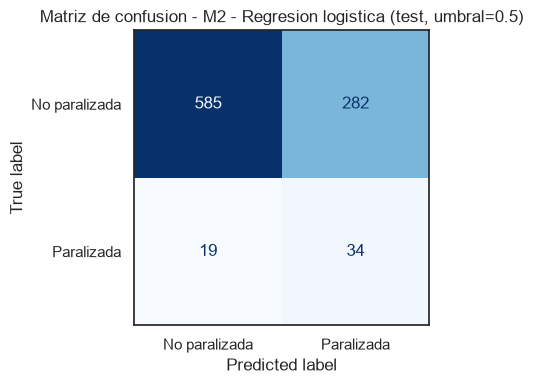

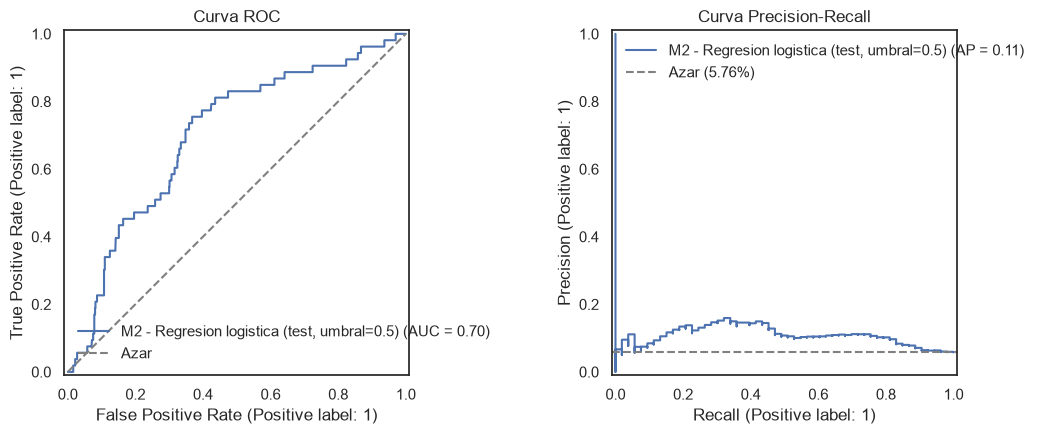

In [556]:
metrics_m2 = reporte_evaluacion(
    y_test_m2, y_pred_m2, y_proba_m2,
    nombre_modelo="M2 - Regresion logistica (test, umbral=0.5)"
)


#### Metricas de entrenamiento (cross-validation 5-fold estratificado) - M2

> Nota: las columnas `tasa_paralizacion_*` se calculan una sola vez sobre todo `df_train_m2` (ver seccion anterior), por lo que cada fold de esta validacion cruzada comparte esa informacion agregada con los demas folds. Esto es una fuga de datos leve (no usa el target de forma directa, solo tasas historicas agregadas) que se resuelve de forma mas rigurosa en `M3` con *time series cross validation*.

In [557]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

scoring_cv = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

skf_m2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results_m2 = cross_validate(
    model_pipeline_m2, X_train_m2, y_train_m2,
    cv=skf_m2, scoring=scoring_cv, n_jobs=-1
)

cv_summary_m2 = pd.DataFrame({m: cv_results_m2[f"test_{m}"] for m in scoring_cv})
cv_summary_m2.index = [f"fold_{i+1}" for i in range(len(cv_summary_m2))]
cv_summary_m2["gini"] = 2 * cv_summary_m2["roc_auc"] - 1
cv_summary_m2.loc["media"] = cv_summary_m2.mean()
cv_summary_m2.loc["std"] = cv_summary_m2.drop(index="media").std()

display(Markdown("**Cross-validation (5-fold estratificado) sobre train - M2**"))
display(Markdown(cv_summary_m2.round(4).to_markdown()))


**Cross-validation (5-fold estratificado) sobre train - M2**

|        |   roc_auc |   pr_auc |   precision |   recall |     f1 |     f2 |   gini |
|:-------|----------:|---------:|------------:|---------:|-------:|-------:|-------:|
| fold_1 |    0.8561 |   0.3881 |      0.2424 |   0.8276 | 0.375  | 0.5581 | 0.7122 |
| fold_2 |    0.8206 |   0.337  |      0.2625 |   0.7241 | 0.3853 | 0.5357 | 0.6413 |
| fold_3 |    0.8853 |   0.4101 |      0.2581 |   0.8571 | 0.3967 | 0.5854 | 0.7707 |
| fold_4 |    0.896  |   0.5085 |      0.2604 |   0.8621 | 0.4    | 0.5896 | 0.792  |
| fold_5 |    0.8387 |   0.4653 |      0.2625 |   0.7241 | 0.3853 | 0.5357 | 0.6775 |
| media  |    0.8594 |   0.4218 |      0.2572 |   0.799  | 0.3885 | 0.5609 | 0.7187 |
| std    |    0.0314 |   0.0668 |      0.0084 |   0.0696 | 0.01   | 0.026  | 0.0629 |

#### Analisis y seleccion del umbral de decision - M2

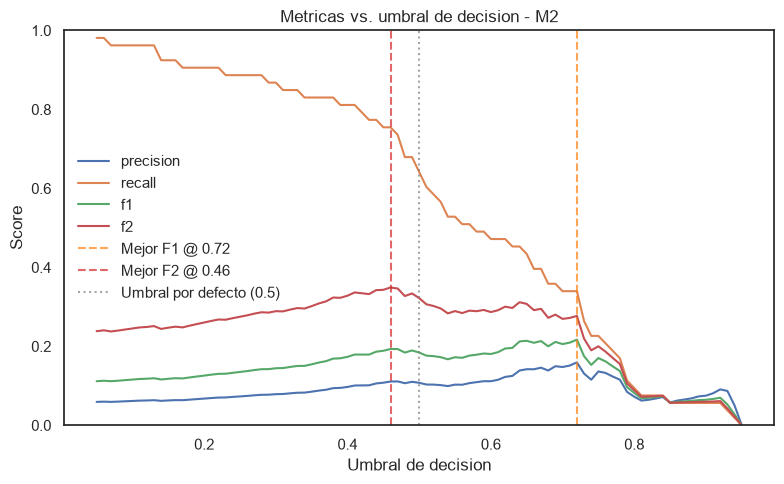

**Mejor umbral por F1 - M2**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.72 |      0.1593 |   0.3396 | 0.2169 | 0.2769 |

**Mejor umbral por F2 (prioriza recall) - M2**

|   umbral |   precision |   recall |     f1 |    f2 |
|---------:|------------:|---------:|-------:|------:|
|     0.46 |      0.1108 |   0.7547 | 0.1932 | 0.349 |

In [558]:
umbrales_m2 = analizar_umbrales(y_test_m2, y_proba_m2)
mejor_f1_m2, mejor_f2_m2 = graficar_umbrales(umbrales_m2, nombre_modelo="M2")

display(Markdown("**Mejor umbral por F1 - M2**"))
display(Markdown(mejor_f1_m2.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M2**"))
display(Markdown(mejor_f2_m2.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M2 - Regresion logistica (test, umbral=0.46)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6994 |
| pr_auc    |  0.1079 |
| gini      |  0.3987 |
| precision |  0.1108 |
| recall    |  0.7547 |
| f1        |  0.1932 |
| f2        |  0.349  |

**Reporte de clasificacion - M2 - Regresion logistica (test, umbral=0.46)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.977 |    0.63  |      0.766 |   867     |
| 1            |       0.111 |    0.755 |      0.193 |    53     |
| accuracy     |       0.637 |    0.637 |      0.637 |     0.637 |
| macro avg    |       0.544 |    0.692 |      0.48  |   920     |
| weighted avg |       0.927 |    0.637 |      0.733 |   920     |

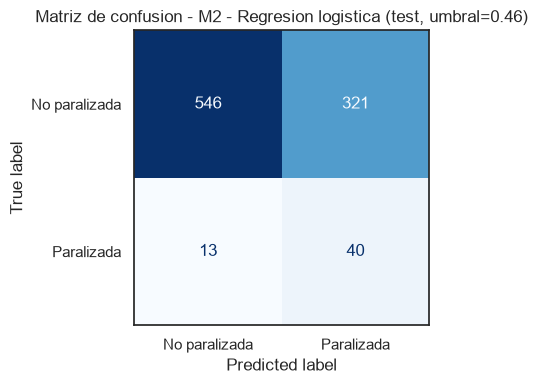

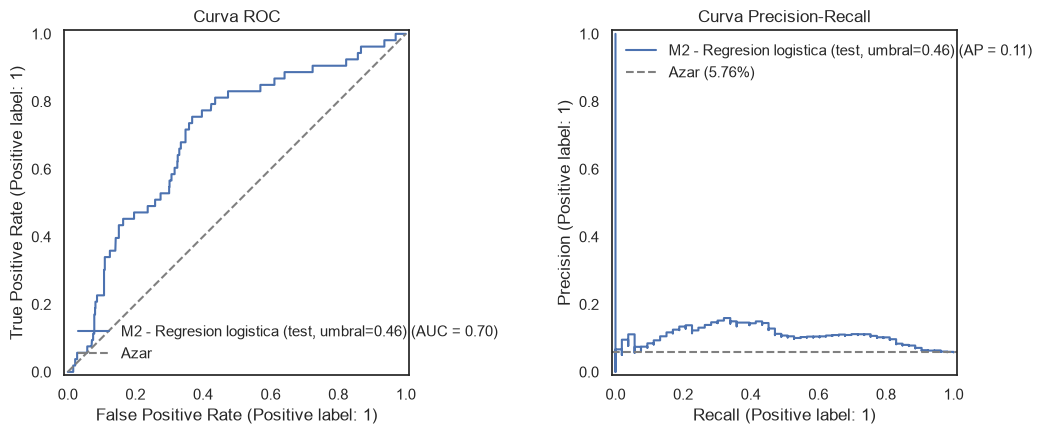

In [559]:
# Editar este valor para explorar manualmente otros umbrales de decision.
# Por defecto se usa el umbral que maximiza F2 (prioriza recall, adecuado
# para el caso de negocio: no queremos dejar pasar obras en riesgo de paralizarse).
UMBRAL_DECISION_M2 = mejor_f2_m2["umbral"]

y_pred_m2_umbral = (y_proba_m2 >= UMBRAL_DECISION_M2).astype(int)

metrics_m2_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m2_umbral, y_proba_m2,
    nombre_modelo=f"M2 - Regresion logistica (test, umbral={UMBRAL_DECISION_M2:.2f})"
)


### M4: GLM binomial con funcion de enlace c-loglog

El link `logit` es simetrico alrededor de p=0.5. Cuando la clase positiva es rara (~7% en este dataset), la probabilidad de paralizacion rara vez se acerca a ese punto y el `logit` tiende a subestimar el riesgo de las obras mas propensas a paralizarse. El enlace **c-loglog** (`log(-log(1-p))`) es asimetrico: se aproxima mas rapido a 1 y mas lento a 0, lo que suele ajustar mejor la cola de eventos raros. Se implementa con `statsmodels` (GLM de la familia Binomial), ya que scikit-learn no ofrece este enlace para clasificacion.

In [560]:
import statsmodels.api as sm

# Se define un preprocesador propio para M4 (no se reutiliza el de M2): al agregar
# una constante para el GLM, un one-hot sin categoria de referencia genera un
# problema de colinealidad perfecta (la suma de las dummies de cada variable
# categorica es igual a la columna de unos), dejando la matriz de diseno con
# rango deficiente. Se usa OneHotEncoder(drop="first") para evitarlo.
amount_log_pipeline_m4 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline_m4 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_m4 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        drop="first",
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

preprocessor_m4 = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline_m4, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline_m4, numeric_standard_cols),
        ("categorical", categorical_pipeline_m4, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)


def construir_matriz_diseno(X, fit=False):
    if fit:
        Xt = preprocessor_m4.fit_transform(X)
    else:
        Xt = preprocessor_m4.transform(X)
    if hasattr(Xt, "toarray"):
        Xt = Xt.toarray()
    return sm.add_constant(Xt, has_constant="add")


X_design_train_m4 = construir_matriz_diseno(X_train_m2, fit=True)
X_design_test_m4 = construir_matriz_diseno(X_test_m2)


In [561]:
glm_m4 = sm.GLM(
    y_train_m2.to_numpy(),
    X_design_train_m4,
    family=sm.families.Binomial(link=sm.families.links.CLogLog())
)
result_m4 = glm_m4.fit()

print(result_m4.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                            GLM   Df Residuals:                     1697
Model Family:                Binomial   Df Model:                            9
Link Function:                CLogLog   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -356.48
Date:                Fri, 04 Sep 2026   Deviance:                       712.97
Time:                        07:21:02   Pearson chi2:                 1.92e+03
No. Iterations:                    10   Pseudo R-squ. (CS):             0.1486
Covariance Type:            nonrobust                                         


**Metricas globales - M4 - GLM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.71   |
| pr_auc    |  0.1177 |
| gini      |  0.42   |
| precision |  0.0833 |
| recall    |  0.0377 |
| f1        |  0.0519 |
| f2        |  0.0424 |

**Reporte de clasificacion - M4 - GLM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.943 |    0.975 |      0.959 |   867     |
| 1            |       0.083 |    0.038 |      0.052 |    53     |
| accuracy     |       0.921 |    0.921 |      0.921 |     0.921 |
| macro avg    |       0.513 |    0.506 |      0.505 |   920     |
| weighted avg |       0.894 |    0.921 |      0.906 |   920     |

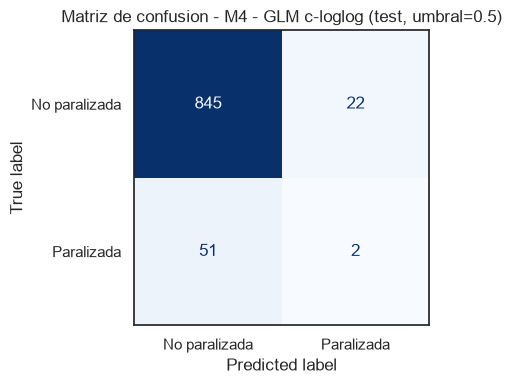

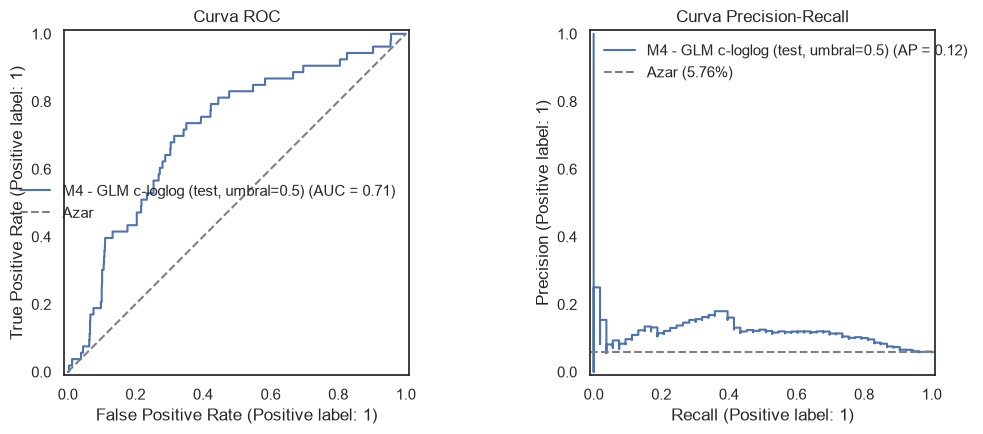

In [562]:
y_proba_m4 = np.asarray(result_m4.predict(X_design_test_m4))
y_pred_m4 = (y_proba_m4 >= 0.5).astype(int)

metrics_m4 = reporte_evaluacion(
    y_test_m2, y_pred_m4, y_proba_m4,
    nombre_modelo="M4 - GLM c-loglog (test, umbral=0.5)"
)


#### Analisis y seleccion del umbral de decision - M4

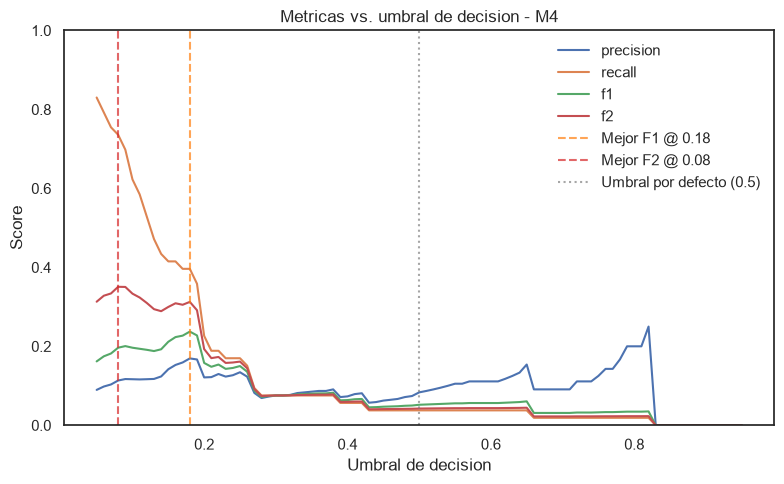

**Mejor umbral por F1 - M4**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.18 |      0.1694 |   0.3962 | 0.2373 | 0.3125 |

**Mejor umbral por F2 (prioriza recall) - M4**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.08 |      0.1134 |   0.7358 | 0.1965 | 0.3507 |

In [563]:
umbrales_m4 = analizar_umbrales(y_test_m2, y_proba_m4)
mejor_f1_m4, mejor_f2_m4 = graficar_umbrales(umbrales_m4, nombre_modelo="M4")

display(Markdown("**Mejor umbral por F1 - M4**"))
display(Markdown(mejor_f1_m4.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M4**"))
display(Markdown(mejor_f2_m4.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M4 - GLM c-loglog (test, umbral=0.08)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.71   |
| pr_auc    |  0.1177 |
| gini      |  0.42   |
| precision |  0.1134 |
| recall    |  0.7358 |
| f1        |  0.1965 |
| f2        |  0.3507 |

**Reporte de clasificacion - M4 - GLM c-loglog (test, umbral=0.08)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.976 |    0.648 |      0.779 |   867     |
| 1            |       0.113 |    0.736 |      0.196 |    53     |
| accuracy     |       0.653 |    0.653 |      0.653 |     0.653 |
| macro avg    |       0.545 |    0.692 |      0.488 |   920     |
| weighted avg |       0.926 |    0.653 |      0.745 |   920     |

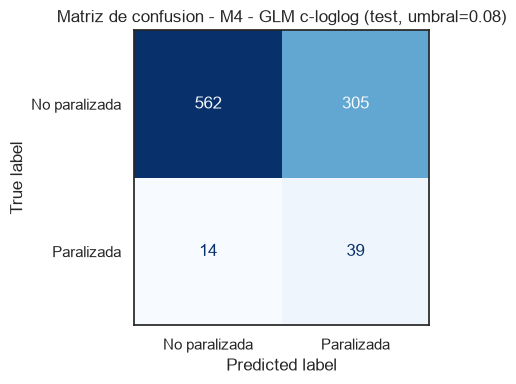

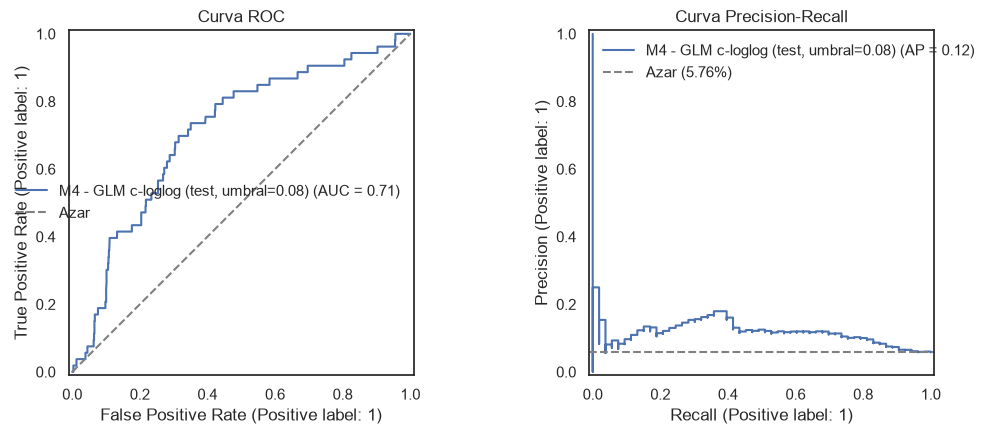

In [564]:
# Editar este valor para explorar manualmente otros umbrales de decision.
UMBRAL_DECISION_M4 = mejor_f2_m4["umbral"]

y_pred_m4_umbral = (y_proba_m4 >= UMBRAL_DECISION_M4).astype(int)

metrics_m4_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m4_umbral, y_proba_m4,
    nombre_modelo=f"M4 - GLM c-loglog (test, umbral={UMBRAL_DECISION_M4:.2f})"
)


#### Comparativa M2 (logit) vs. M4 (c-loglog), umbral=0.5

In [565]:
comparativa_m2_m4 = pd.DataFrame(
    [metrics_m2, metrics_m4],
    index=["M2 - Regresion logistica", "M4 - GLM c-loglog"]
)
display(Markdown(comparativa_m2_m4.round(4).to_markdown()))


|                          |   roc_auc |   pr_auc |   gini |   precision |   recall |     f1 |     f2 |
|:-------------------------|----------:|---------:|-------:|------------:|---------:|-------:|-------:|
| M2 - Regresion logistica |    0.6994 |   0.1079 | 0.3987 |      0.1076 |   0.6415 | 0.1843 | 0.322  |
| M4 - GLM c-loglog        |    0.71   |   0.1177 | 0.42   |      0.0833 |   0.0377 | 0.0519 | 0.0424 |

### M6 y M7: GAM (Generalized Additive Model)

Un GAM reemplaza el termino lineal `beta * x` de un GLM por una funcion suave `f(x)` (splines) para las variables continuas, permitiendo relaciones no lineales entre cada variable y el riesgo de paralizacion sin perder la interpretabilidad de un modelo aditivo. Se implementa con `statsmodels.gam` (`GLMGam` + `BSplines`). Las variables categoricas entran igual que en M4 (dummies con categoria de referencia); las variables continuas (`amount_log_cols` + `numeric_standard_cols`) entran como terminos suaves.

- `M6`: enlace `logit` (simetrico).
- `M7`: enlace `c-loglog` (asimetrico, igual que M4, favorece la clase rara).

Ambos modelos comparten el mismo preprocesamiento y la misma base de splines (ajustada solo sobre train); solo cambia la familia/enlace del GLM.

In [566]:
from statsmodels.gam.api import GLMGam, BSplines

# Preprocesador propio para GAM (misma logica que M4: drop="first" para evitar
# colinealidad con la constante del modelo lineal por partes).
amount_log_pipeline_gam = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline_gam = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_gam = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        drop="first",
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

preprocessor_gam = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline_gam, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline_gam, numeric_standard_cols),
        ("categorical", categorical_pipeline_gam, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

Xt_train_gam = preprocessor_gam.fit_transform(X_train_m2)
Xt_test_gam = preprocessor_gam.transform(X_test_m2)
if hasattr(Xt_train_gam, "toarray"):
    Xt_train_gam = Xt_train_gam.toarray()
    Xt_test_gam = Xt_test_gam.toarray()

# Las primeras columnas (amount_log + numeric_standard) son continuas -> splines.
# El resto son dummies de las variables categoricas -> parte lineal.
n_suaves = len(amount_log_cols) + len(numeric_standard_cols)

X_smooth_train = Xt_train_gam[:, :n_suaves]
X_linear_train = Xt_train_gam[:, n_suaves:]
X_smooth_test = Xt_test_gam[:, :n_suaves]
X_linear_test = Xt_test_gam[:, n_suaves:]

# Los splines de statsmodels no soportan extrapolar fuera de los knots (definidos
# con train); como el split es temporal, el test puede traer valores fuera de ese
# rango, asi que se recortan a los limites observados en train antes de predecir.
limite_inf_gam = X_smooth_train.min(axis=0)
limite_sup_gam = X_smooth_train.max(axis=0)
X_smooth_test = np.clip(X_smooth_test, limite_inf_gam, limite_sup_gam)

bs_gam = BSplines(X_smooth_train, df=[5] * n_suaves, degree=[3] * n_suaves)

X_linear_train_const = sm.add_constant(X_linear_train, has_constant="add")
X_linear_test_const = sm.add_constant(X_linear_test, has_constant="add")


#### M6: GAM con enlace logit

In [567]:
gam_m6 = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.Probit()), # Logit
    alpha=1.0
)
result_m6 = gam_m6.fit()

print(result_m6.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                         GLMGam   Df Residuals:                  1689.73
Model Family:                Binomial   Df Model:                        16.27
Link Function:                 Probit   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -343.18
Date:                Fri, 04 Sep 2026   Deviance:                       686.35
Time:                        07:21:06   Pearson chi2:                 2.01e+03
No. Iterations:                    13   Pseudo R-squ. (CS):             0.1618
Covariance Type:            nonrobust                                         


**Metricas globales - M6 - GAM logit (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.73   |
| pr_auc    |  0.1369 |
| gini      |  0.4599 |
| precision |  0.08   |
| recall    |  0.0377 |
| f1        |  0.0513 |
| f2        |  0.0422 |

**Reporte de clasificacion - M6 - GAM logit (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.943 |    0.973 |      0.958 |    867    |
| 1            |       0.08  |    0.038 |      0.051 |     53    |
| accuracy     |       0.92  |    0.92  |      0.92  |      0.92 |
| macro avg    |       0.512 |    0.506 |      0.505 |    920    |
| weighted avg |       0.893 |    0.92  |      0.906 |    920    |

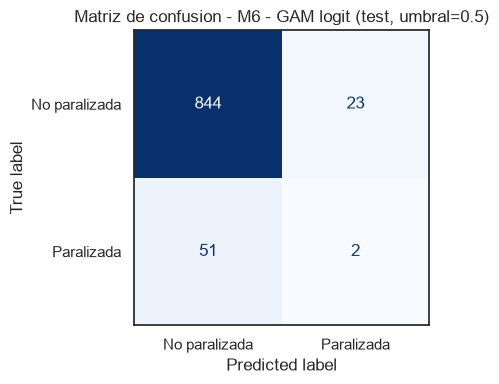

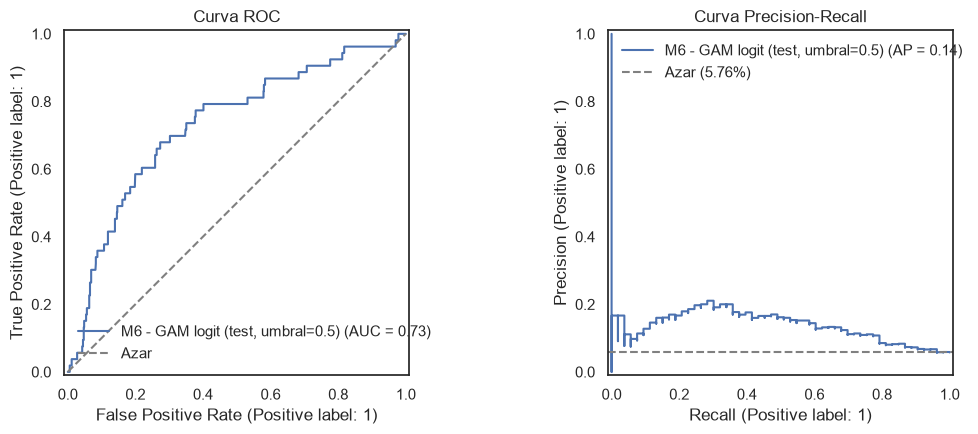

In [568]:
y_proba_m6 = np.asarray(result_m6.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m6 = (y_proba_m6 >= 0.5).astype(int)

metrics_m6 = reporte_evaluacion(
    y_test_m2, y_pred_m6, y_proba_m6,
    nombre_modelo="M6 - GAM logit (test, umbral=0.5)"
)


#### Analisis y seleccion del umbral de decision - M6

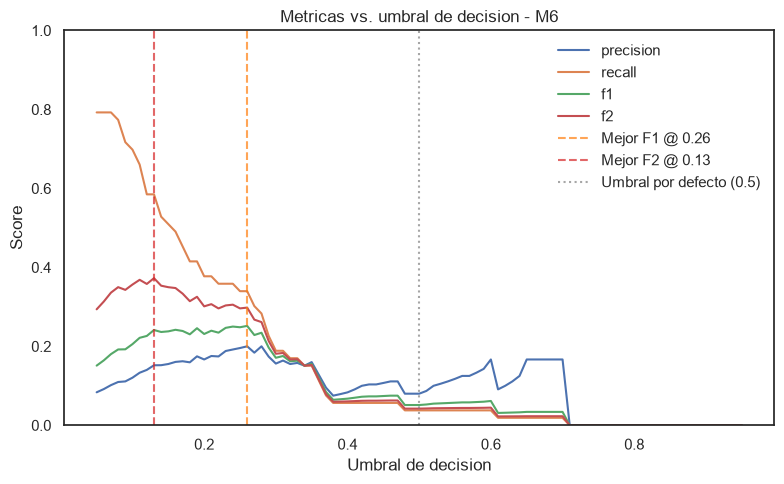

**Mejor umbral por F1 - M6**

|   umbral |   precision |   recall |     f1 |    f2 |
|---------:|------------:|---------:|-------:|------:|
|     0.26 |         0.2 |   0.3396 | 0.2517 | 0.298 |

**Mejor umbral por F2 (prioriza recall) - M6**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.13 |       0.152 |   0.5849 | 0.2412 | 0.3726 |

In [569]:
umbrales_m6 = analizar_umbrales(y_test_m2, y_proba_m6)
mejor_f1_m6, mejor_f2_m6 = graficar_umbrales(umbrales_m6, nombre_modelo="M6")

display(Markdown("**Mejor umbral por F1 - M6**"))
display(Markdown(mejor_f1_m6.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M6**"))
display(Markdown(mejor_f2_m6.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M6 - GAM logit (test, umbral=0.13)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.73   |
| pr_auc    |  0.1369 |
| gini      |  0.4599 |
| precision |  0.152  |
| recall    |  0.5849 |
| f1        |  0.2412 |
| f2        |  0.3726 |

**Reporte de clasificacion - M6 - GAM logit (test, umbral=0.13)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.969 |    0.8   |      0.877 |   867     |
| 1            |       0.152 |    0.585 |      0.241 |    53     |
| accuracy     |       0.788 |    0.788 |      0.788 |     0.788 |
| macro avg    |       0.561 |    0.693 |      0.559 |   920     |
| weighted avg |       0.922 |    0.788 |      0.84  |   920     |

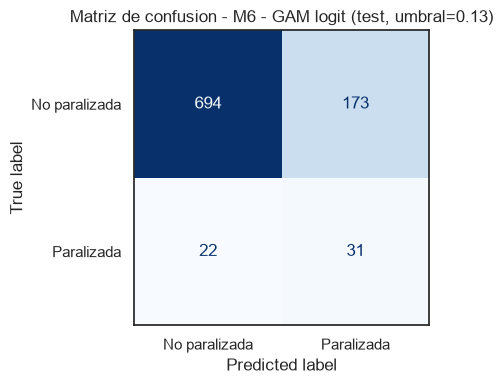

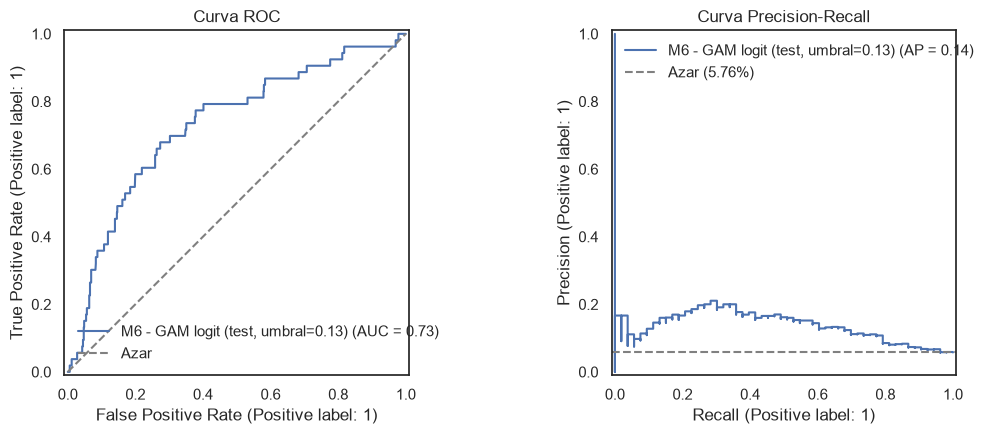

In [570]:
UMBRAL_DECISION_M6 = mejor_f2_m6["umbral"]

y_pred_m6_umbral = (y_proba_m6 >= UMBRAL_DECISION_M6).astype(int)

metrics_m6_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m6_umbral, y_proba_m6,
    nombre_modelo=f"M6 - GAM logit (test, umbral={UMBRAL_DECISION_M6:.2f})"
)


#### M7: GAM con enlace c-loglog

In [571]:
gam_m7 = GLMGam(
    y_train_m2.to_numpy(),
    exog=X_linear_train_const,
    smoother=bs_gam,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    alpha=1.0
)
result_m7 = gam_m7.fit()

print(result_m7.summary().tables[0])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1707
Model:                         GLMGam   Df Residuals:                  1691.43
Model Family:                Binomial   Df Model:                        14.57
Link Function:                CLogLog   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -342.21
Date:                Fri, 04 Sep 2026   Deviance:                       684.42
Time:                        07:21:08   Pearson chi2:                 2.12e+03
No. Iterations:                    19   Pseudo R-squ. (CS):             0.1627
Covariance Type:            nonrobust                                         


**Metricas globales - M7 - GAM c-loglog (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7353 |
| pr_auc    |  0.1499 |
| gini      |  0.4706 |
| precision |  0.1304 |
| recall    |  0.0566 |
| f1        |  0.0789 |
| f2        |  0.0638 |

**Reporte de clasificacion - M7 - GAM c-loglog (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.944 |    0.977 |      0.96  |   867     |
| 1            |       0.13  |    0.057 |      0.079 |    53     |
| accuracy     |       0.924 |    0.924 |      0.924 |     0.924 |
| macro avg    |       0.537 |    0.517 |      0.52  |   920     |
| weighted avg |       0.897 |    0.924 |      0.91  |   920     |

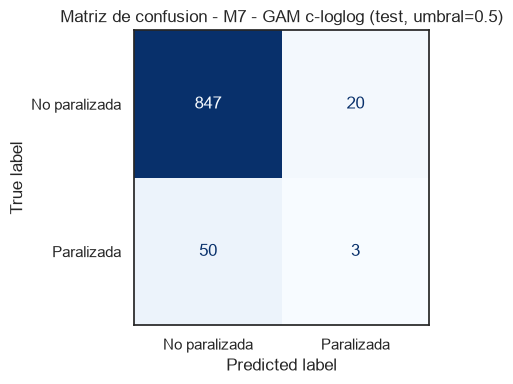

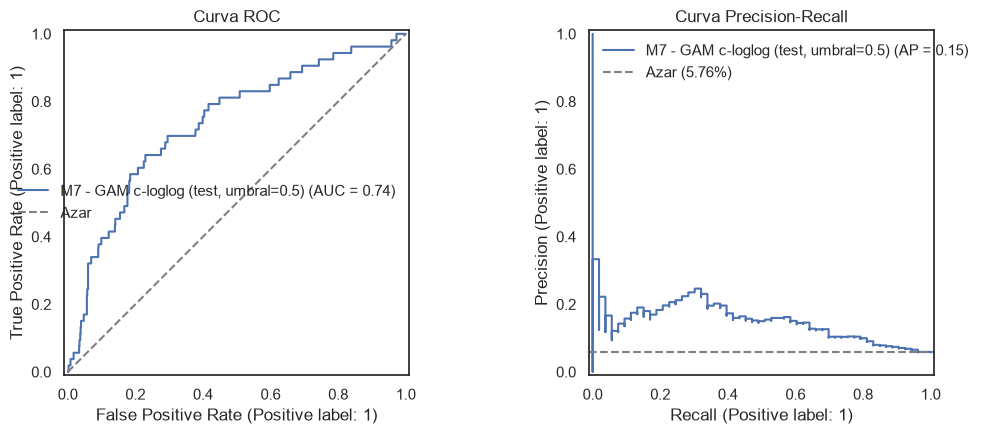

In [572]:
y_proba_m7 = np.asarray(result_m7.predict(exog=X_linear_test_const, exog_smooth=X_smooth_test))
y_pred_m7 = (y_proba_m7 >= 0.5).astype(int)

metrics_m7 = reporte_evaluacion(
    y_test_m2, y_pred_m7, y_proba_m7,
    nombre_modelo="M7 - GAM c-loglog (test, umbral=0.5)"
)


#### Analisis y seleccion del umbral de decision - M7

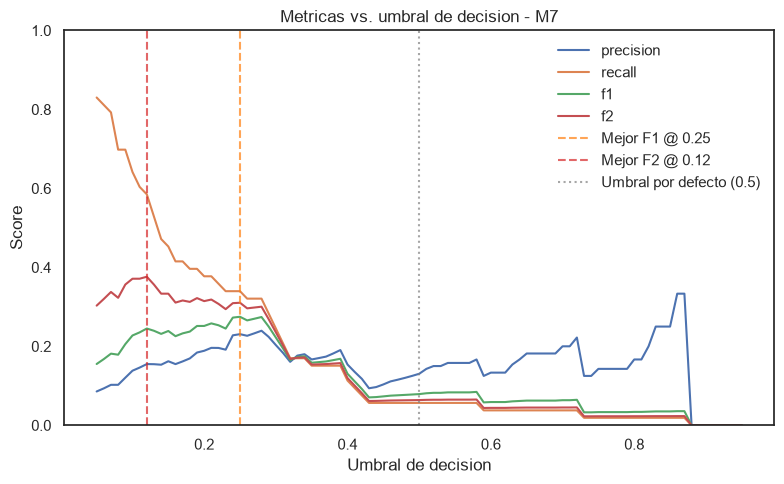

**Mejor umbral por F1 - M7**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.25 |      0.2308 |   0.3396 | 0.2748 | 0.3103 |

**Mejor umbral por F2 (prioriza recall) - M7**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.12 |       0.155 |   0.5849 | 0.2451 | 0.3762 |

In [573]:
umbrales_m7 = analizar_umbrales(y_test_m2, y_proba_m7)
mejor_f1_m7, mejor_f2_m7 = graficar_umbrales(umbrales_m7, nombre_modelo="M7")

display(Markdown("**Mejor umbral por F1 - M7**"))
display(Markdown(mejor_f1_m7.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - M7**"))
display(Markdown(mejor_f2_m7.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - M7 - GAM c-loglog (test, umbral=0.12)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.7353 |
| pr_auc    |  0.1499 |
| gini      |  0.4706 |
| precision |  0.155  |
| recall    |  0.5849 |
| f1        |  0.2451 |
| f2        |  0.3762 |

**Reporte de clasificacion - M7 - GAM c-loglog (test, umbral=0.12)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.969 |    0.805 |      0.88  |   867     |
| 1            |       0.155 |    0.585 |      0.245 |    53     |
| accuracy     |       0.792 |    0.792 |      0.792 |     0.792 |
| macro avg    |       0.562 |    0.695 |      0.562 |   920     |
| weighted avg |       0.923 |    0.792 |      0.843 |   920     |

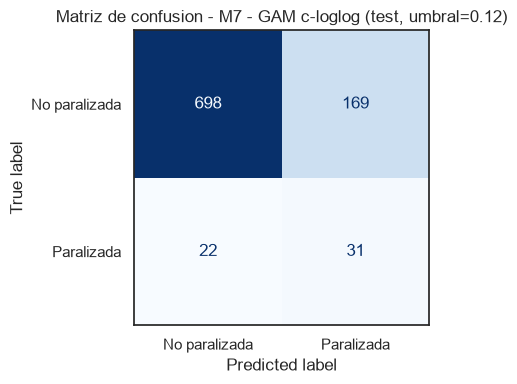

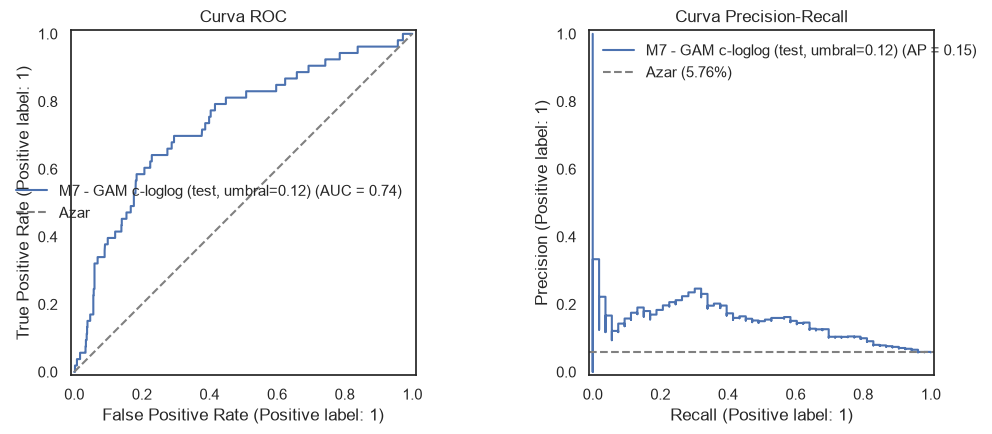

In [574]:
UMBRAL_DECISION_M7 = mejor_f2_m7["umbral"]

y_pred_m7_umbral = (y_proba_m7 >= UMBRAL_DECISION_M7).astype(int)

metrics_m7_umbral = reporte_evaluacion(
    y_test_m2, y_pred_m7_umbral, y_proba_m7,
    nombre_modelo=f"M7 - GAM c-loglog (test, umbral={UMBRAL_DECISION_M7:.2f})"
)


### Benchmark de Machine Learning: Random Forest

Como referencia no lineal / no parametrica frente a los modelos GLM/GAM anteriores. Para el desbalance de clases se usa `class_weight="balanced_subsample"` (pondera cada arbol segun el bootstrap de esa iteracion) en lugar de sobre/sub-muestreo explicito.

In [575]:
from sklearn.ensemble import RandomForestClassifier

amount_log_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

preprocessor_rf = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline_rf, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline_rf, numeric_standard_cols),
        ("categorical", categorical_pipeline_rf, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

classifier_rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model_pipeline_rf = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", classifier_rf)
])

model_pipeline_rf.fit(X_train_m2, y_train_m2)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['monto_aprobado_soles','n_obras_x_entidad', 'tasa_paralizacion_departamento',...,'tasa_paralizacion_sector_entidad', 'monto_aprobado_soles_log','tipo_formato']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('amount_log', ...), ('numeric_standard', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the outp

**Metricas globales - RF - Random Forest benchmark (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6944 |
| pr_auc    |  0.2138 |
| gini      |  0.3889 |
| precision |  0.1826 |
| recall    |  0.3962 |
| f1        |  0.25   |
| f2        |  0.3211 |

**Reporte de clasificacion - RF - Random Forest benchmark (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.96  |    0.892 |      0.925 |   867     |
| 1            |       0.183 |    0.396 |      0.25  |    53     |
| accuracy     |       0.863 |    0.863 |      0.863 |     0.863 |
| macro avg    |       0.571 |    0.644 |      0.587 |   920     |
| weighted avg |       0.915 |    0.863 |      0.886 |   920     |

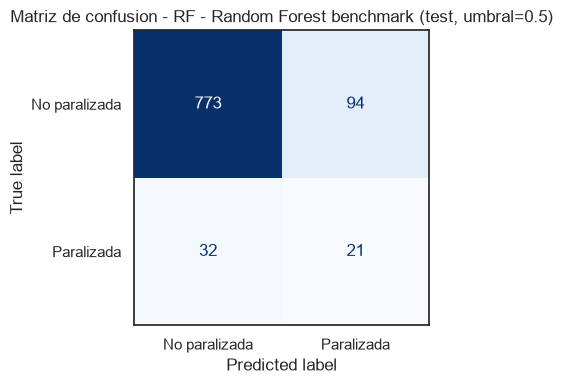

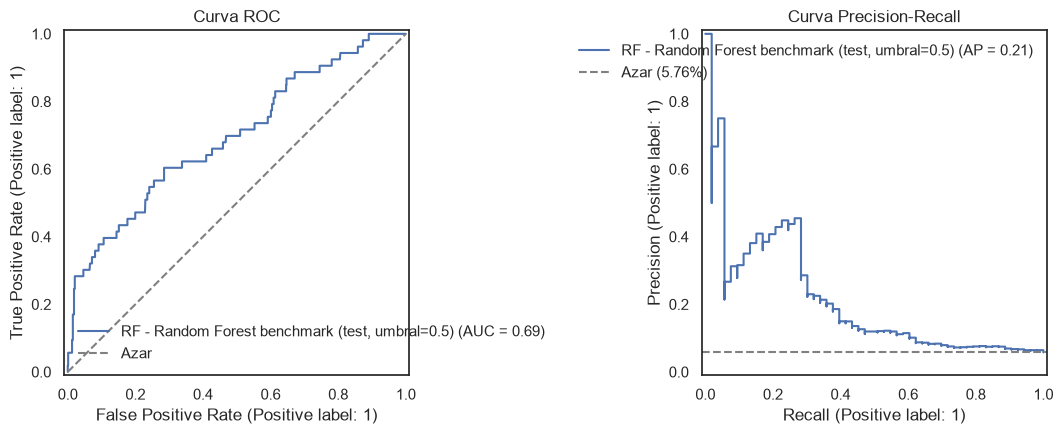

In [576]:
y_pred_rf = model_pipeline_rf.predict(X_test_m2)
y_proba_rf = model_pipeline_rf.predict_proba(X_test_m2)[:, 1]

metrics_rf = reporte_evaluacion(
    y_test_m2, y_pred_rf, y_proba_rf,
    nombre_modelo="RF - Random Forest benchmark (test, umbral=0.5)"
)


#### Metricas de entrenamiento (cross-validation 5-fold estratificado) - Random Forest

In [577]:
skf_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results_rf = cross_validate(
    model_pipeline_rf, X_train_m2, y_train_m2,
    cv=skf_rf, scoring=scoring_cv, n_jobs=-1
)

cv_summary_rf = pd.DataFrame({m: cv_results_rf[f"test_{m}"] for m in scoring_cv})
cv_summary_rf.index = [f"fold_{i+1}" for i in range(len(cv_summary_rf))]
cv_summary_rf["gini"] = 2 * cv_summary_rf["roc_auc"] - 1
cv_summary_rf.loc["media"] = cv_summary_rf.mean()
cv_summary_rf.loc["std"] = cv_summary_rf.drop(index="media").std()

display(Markdown("**Cross-validation (5-fold estratificado) sobre train - Random Forest**"))
display(Markdown(cv_summary_rf.round(4).to_markdown()))


**Cross-validation (5-fold estratificado) sobre train - Random Forest**

|        |   roc_auc |   pr_auc |   precision |   recall |     f1 |     f2 |   gini |
|:-------|----------:|---------:|------------:|---------:|-------:|-------:|-------:|
| fold_1 |    0.874  |   0.4282 |      0.3019 |   0.5517 | 0.3902 | 0.4734 | 0.7479 |
| fold_2 |    0.8291 |   0.461  |      0.3061 |   0.5172 | 0.3846 | 0.4545 | 0.6581 |
| fold_3 |    0.8872 |   0.4909 |      0.2963 |   0.5714 | 0.3902 | 0.4819 | 0.7743 |
| fold_4 |    0.9126 |   0.5913 |      0.3279 |   0.6897 | 0.4444 | 0.565  | 0.8252 |
| fold_5 |    0.8836 |   0.5533 |      0.381  |   0.5517 | 0.4507 | 0.5063 | 0.7672 |
| media  |    0.8773 |   0.5049 |      0.3226 |   0.5764 | 0.4121 | 0.4962 | 0.7546 |
| std    |    0.0305 |   0.0667 |      0.0347 |   0.0663 | 0.0326 | 0.0427 | 0.061  |

#### Analisis y seleccion del umbral de decision - Random Forest

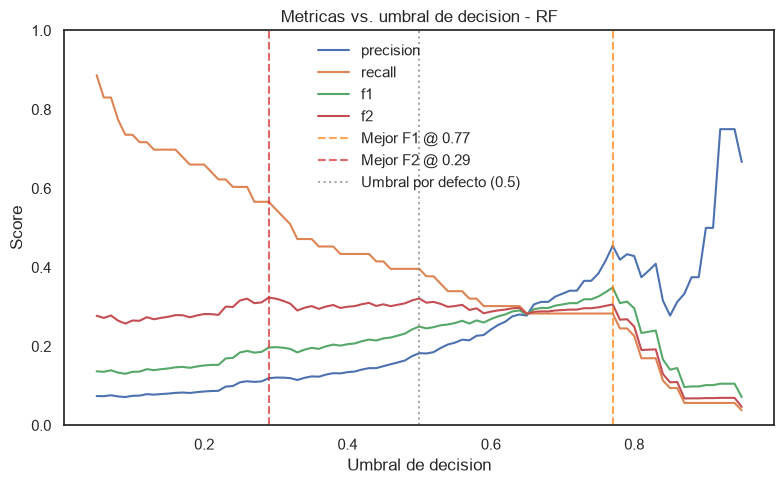

**Mejor umbral por F1 - RF**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.77 |      0.4545 |    0.283 | 0.3488 | 0.3061 |

**Mejor umbral por F2 (prioriza recall) - RF**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.29 |       0.119 |    0.566 | 0.1967 | 0.3233 |

In [578]:
umbrales_rf = analizar_umbrales(y_test_m2, y_proba_rf)
mejor_f1_rf, mejor_f2_rf = graficar_umbrales(umbrales_rf, nombre_modelo="RF")

display(Markdown("**Mejor umbral por F1 - RF**"))
display(Markdown(mejor_f1_rf.to_frame().T.round(4).to_markdown(index=False)))

display(Markdown("**Mejor umbral por F2 (prioriza recall) - RF**"))
display(Markdown(mejor_f2_rf.to_frame().T.round(4).to_markdown(index=False)))


**Metricas globales - RF - Random Forest benchmark (test, umbral=0.29)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.6944 |
| pr_auc    |  0.2138 |
| gini      |  0.3889 |
| precision |  0.119  |
| recall    |  0.566  |
| f1        |  0.1967 |
| f2        |  0.3233 |

**Reporte de clasificacion - RF - Random Forest benchmark (test, umbral=0.29)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.966 |    0.744 |      0.84  |   867     |
| 1            |       0.119 |    0.566 |      0.197 |    53     |
| accuracy     |       0.734 |    0.734 |      0.734 |     0.734 |
| macro avg    |       0.542 |    0.655 |      0.519 |   920     |
| weighted avg |       0.917 |    0.734 |      0.803 |   920     |

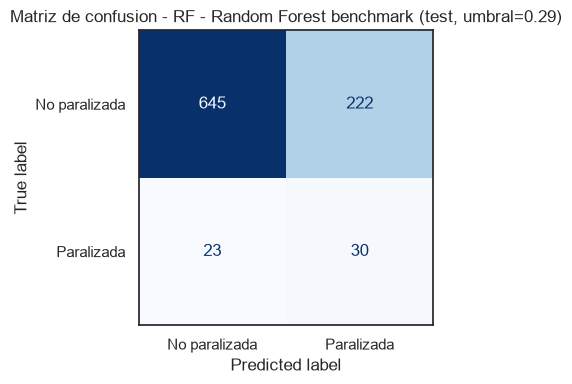

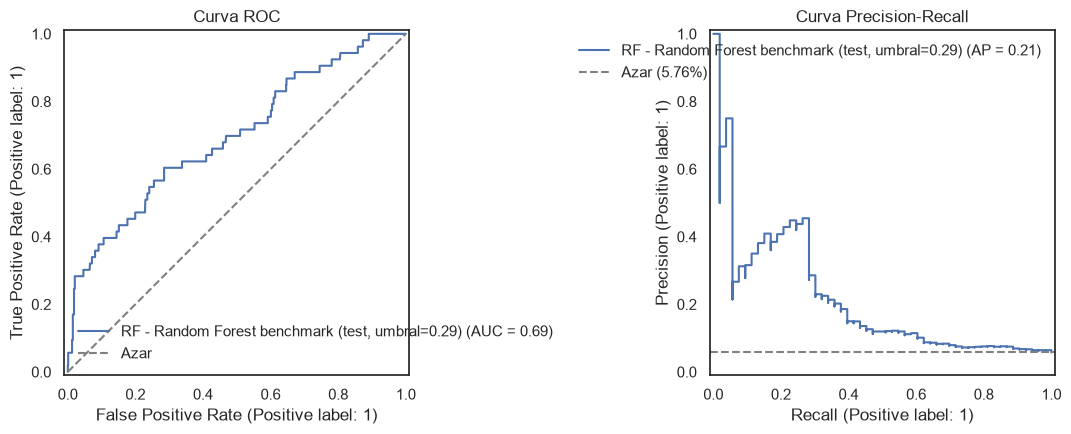

In [579]:
UMBRAL_DECISION_RF = mejor_f2_rf["umbral"]

y_pred_rf_umbral = (y_proba_rf >= UMBRAL_DECISION_RF).astype(int)

metrics_rf_umbral = reporte_evaluacion(
    y_test_m2, y_pred_rf_umbral, y_proba_rf,
    nombre_modelo=f"RF - Random Forest benchmark (test, umbral={UMBRAL_DECISION_RF:.2f})"
)


### Comparativa general (M2, M4, M6, M7, RF) - test, umbral=0.5

In [580]:
comparativa_modelos = pd.DataFrame(
    [metrics_m2, metrics_m4, metrics_m6, metrics_m7, metrics_rf],
    index=[
        "M2 - Regresion logistica",
        "M4 - GLM c-loglog",
        "M6 - GAM logit",
        "M7 - GAM c-loglog",
        "RF - Random Forest"
    ]
)
display(Markdown(comparativa_modelos.round(4).to_markdown()))


|                          |   roc_auc |   pr_auc |   gini |   precision |   recall |     f1 |     f2 |
|:-------------------------|----------:|---------:|-------:|------------:|---------:|-------:|-------:|
| M2 - Regresion logistica |    0.6994 |   0.1079 | 0.3987 |      0.1076 |   0.6415 | 0.1843 | 0.322  |
| M4 - GLM c-loglog        |    0.71   |   0.1177 | 0.42   |      0.0833 |   0.0377 | 0.0519 | 0.0424 |
| M6 - GAM logit           |    0.73   |   0.1369 | 0.4599 |      0.08   |   0.0377 | 0.0513 | 0.0422 |
| M7 - GAM c-loglog        |    0.7353 |   0.1499 | 0.4706 |      0.1304 |   0.0566 | 0.0789 | 0.0638 |
| RF - Random Forest       |    0.6944 |   0.2138 | 0.3889 |      0.1826 |   0.3962 | 0.25   | 0.3211 |

### Cerrar conexión a la BD

In [41]:
# =============================================================================
# Cerrar conexión a la base de datos
# =============================================================================

if pg_conn:
    pg_conn.close()
    print("✓ Conexión a PostgreSQL cerrada")

✓ Conexión a PostgreSQL cerrada
